# Predicción de sobrecostos en contratos públicos (SECOP II)

**Trabajo final · Machine Learning I · Maestría**

**Pregunta:** en el momento de **adjudicar** un proceso de contratación, ¿podemos anticipar si el contrato terminará costando más de lo adjudicado?

> **Alcance del modelo.** El objetivo compara el valor final del contrato con su **valor adjudicado**, y la *Contratación directa* y la *Contratación régimen especial* **sin ofertas** no tienen valor adjudicado registrado en *Procesos* (sección 4.5). Esas dos modalidades son cerca del 90 % de los contratos del SECOP II, así que **el modelo solo aplica a los contratos de modalidades competitivas y a las variantes «con ofertas»**: no predice sobrecostos en la contratación directa sin ofertas. La sección 4.5 calcula la cobertura exacta del período.

**Datos** (datos abiertos, [datos.gov.co](https://www.datos.gov.co)):

| Conjunto | ID | Qué aporta |
|---|---|---|
| [SECOP II - Contratos Electrónicos](https://www.datos.gov.co/Estad-sticas-Nacionales/SECOP-II-Contratos-Electr-nicos/jbjy-vk9h) | `jbjy-vk9h` | el contrato: entidad, proveedor, tipo, **valor del contrato (incluye adiciones)** |
| [SECOP II - Procesos de Contratación](https://www.datos.gov.co/Estad-sticas-Nacionales/SECOP-II-Procesos-de-Contrataci-n/p6dx-8zbt) | `p6dx-8zbt` | el proceso: precio base, **valor adjudicado**, duración, competencia |
| [SECOP II - Adiciones](https://www.datos.gov.co/Gastos-Gubernamentales/SECOP-II-Adiciones/cb9c-h8sn) | `cb9c-h8sn` | fechas de las modificaciones: para el **tope legal** (sección 4.2) y para **validar** el objetivo (sección 4.3); no trae montos |

**Diseño temporal:** se entrena con contratos firmados entre **2021 y 2023** y se evalúa con contratos firmados en **2024**, como si el modelo se hubiera construido a comienzos de 2024 y se usara durante ese año. Una segunda ventana (entrenar 2021-2022, evaluar 2023) sirve para verificar que el resultado no depende de un solo año. Solo entran contratos **ya terminados** (su fecha de fin pasó), para que la etiqueta no cambie después de la descarga.

**Variable objetivo (sobrecosto):**

$$\text{sobrecosto} = \mathbb{1}\left[\ \texttt{valor\_del\_contrato} > \texttt{valor\_total\_adjudicacion}\ \right]$$

Es decir, el contrato **creció después de adjudicado** (adiciones en valor). En SECOP II `valor_del_contrato` se actualiza con las adiciones; la sección 4 lo verifica con el tope legal de adiciones y con el conjunto de adiciones.

**Regla de oro:** el modelo solo puede usar información **disponible al adjudicar**. Se excluyen identificadores y cualquier columna que se actualice durante la ejecución del contrato (fuga de información).

**Estructura:** 1-3 datos · 4 objetivo y validaciones · 5 variables · 6 partición temporal y validación cruzada por entidad · 7 marco de evaluación · 8 modelos (logística, árbol, bosque aleatorio, gradient boosting) · 9 red neuronal · 10 selección automática del campeón, comparación en prueba y curva de aprendizaje · 11 importancia · 12 robustez (corte del objetivo y segunda ventana temporal) · 13 fuga · 14 conclusiones y limitaciones.

## 1. Configuración

In [ ]:
import io, time, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

ANIOS_ENTRENAMIENTO = [2021, 2022, 2023]   # años de firma para entrenar
ANIO_PRUEBA = 2024                         # año de firma para evaluar (nunca se usa para decidir nada)
VENTANA_2 = ([2021, 2022], 2023)           # segunda ventana temporal, solo para robustez (sección 12)
ANIOS = ANIOS_ENTRENAMIENTO + [ANIO_PRUEBA]
MARGEN_DIAS = 30                     # solo contratos cuya fecha de fin pasó hace al menos este margen
FECHA_DESCARGA = pd.Timestamp("2026-10-19")   # fecha fija de referencia: reproduce la corrida reportada.
                                              # Para actualizar con datos nuevos: pd.Timestamp.today().normalize()
SEMILLA = 42
N_PLIEGUES = 5           # validación cruzada agrupada por entidad, solo dentro de entrenamiento
BETA = 1.0               # umbral: maximiza F-beta en predicciones fuera de pliegue (BETA > 1 prioriza exhaustividad)
CORTE_PRINCIPAL = "legal"   # "legal": tope de la Ley 80 en SMMLV · "nominal": 1,5x en pesos
TOPE_ERROR = 3.0         # régimen especial (sin tope de Ley 80): crecer más de 3x se trata como error de registro
N_BOOT = 500             # remuestreos bootstrap por entidad para los intervalos de confianza
CAPACIDAD = 0.10         # fracción de contratos que se podrían revisar: para la precisión en los primeros k

API = "https://www.datos.gov.co/resource/{}.csv"
CONTRATOS, PROCESOS, ADICIONES = "jbjy-vk9h", "p6dx-8zbt", "cb9c-h8sn"
DESDE, HASTA = f"{min(ANIOS)}-01-01", f"{max(ANIOS)}-12-31T23:59:59"

# Salario mínimo mensual legal vigente, en pesos (2026: Decreto 1469 de 2025).
SMMLV = {2020: 877_803, 2021: 908_526, 2022: 1_000_000, 2023: 1_160_000, 2024: 1_300_000,
         2025: 1_423_500, 2026: 1_750_905}

## 2. Descarga de datos (API Socrata)

Se descargan solo las columnas necesarias, paginando de a 50.000 filas.

* **Contratos** firmados entre 2021 y 2024, sin *Contratación directa* ni *Contratación régimen especial* **sin ofertas** (no tienen valor adjudicado; sección 4.5). Las variantes *con ofertas* de esas dos modalidades sí entran.
* **Procesos adjudicados** publicados entre el año anterior al primer año y el último año (un contrato firmado en enero pudo publicarse meses antes).

> Los identificadores (`proceso_de_compra`, `id_del_portafolio`, `id_contrato`, `nit_entidad`) se descargan **solo para unir las tablas, validar y agrupar por entidad**; nunca entran al modelo.

In [96]:
COLS_CONTRATOS = [
    # llaves (solo para unir / agrupar / validar)
    "proceso_de_compra", "id_contrato", "nit_entidad",
    # objetivo
    "valor_del_contrato",
    # candidatas (conocidas al adjudicar/firmar)
    "departamento", "orden", "sector", "rama", "entidad_centralizada", "tipo_de_contrato",
    "modalidad_de_contratacion", "codigo_de_categoria_principal", "origen_de_los_recursos",
    "destino_gasto", "es_pyme", "es_grupo", "tipodocproveedor", "habilita_pago_adelantado",
    "el_contrato_puede_ser_prorrogado", "espostconflicto", "obligaci_n_ambiental", "reversion",
    "liquidaci_n", "documentos_tipo", "fecha_de_firma",
    # columnas con fuga: se descargan SOLO para filtrar, validar y demostrar el efecto en la sección 13
    "estado_contrato", "dias_adicionados", "presupuesto_general_de_la_nacion_pgn",
    "recursos_propios", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato",
    "valor_facturado", "valor_pagado",
]
COLS_PROCESOS = [
    "id_del_portafolio", "precio_base", "valor_total_adjudicacion", "duracion", "unidad_de_duracion",
    "numero_de_lotes", "proveedores_invitados", "proveedores_con_invitacion",
    "respuestas_al_procedimiento", "proveedores_unicos_con", "fecha_de_ultima_publicaci",
]
SIN_OFERTAS = "('Contratación directa','Contratación régimen especial')"


def _get(url, params):
    """GET con reintentos; una consulta mal formada (400) se reporta de inmediato."""
    for intento in range(5):
        try:
            r = requests.get(url, params=params, timeout=300)
            if r.status_code == 400:
                raise ValueError(f"La API rechazó la consulta: {r.text[:300]}")
            r.raise_for_status()
            return r
        except requests.RequestException:
            time.sleep(2 ** intento)
    raise RuntimeError(f"No se pudo descargar {url} con {params}")


def descargar(dataset, where, columnas, pagina=50_000, max_filas=None):
    """Descarga paginada; max_filas limita el total (para muestras de diagnóstico)."""
    partes, offset = [], 0
    while True:
        limite = pagina if max_filas is None else min(pagina, max_filas - offset)
        params = {"$select": ",".join(columnas), "$where": where, "$order": ":id",
                  "$limit": limite, "$offset": offset}
        df = pd.read_csv(io.StringIO(_get(API.format(dataset), params).text), dtype=str)
        partes.append(df)
        print(f"  {dataset}: offset={offset:>7,}  filas={len(df):,}")
        offset += len(df)
        if len(df) < limite or (max_filas is not None and offset >= max_filas):
            return pd.concat(partes, ignore_index=True)


def descargar_por_ids(dataset, campo, ids, columnas=None, lote=150):
    """Descarga solo las filas cuyas llaves están en `ids`, en lotes (para no exceder el largo de la URL)."""
    ids = list(dict.fromkeys(i for i in ids if isinstance(i, str)))
    partes = []
    for i in range(0, len(ids), lote):
        lista = ",".join("'" + x.replace("'", "''") + "'" for x in ids[i:i + lote])
        params = {"$where": f"{campo} in ({lista})", "$limit": 50_000}
        if columnas:
            params["$select"] = ",".join(columnas)
        partes.append(pd.read_csv(io.StringIO(_get(API.format(dataset), params).text), dtype=str))
    salida = pd.concat(partes, ignore_index=True) if partes else pd.DataFrame(columns=columnas or [])
    print(f"  {dataset}: {len(ids):,} llaves consultadas -> {len(salida):,} filas")
    return salida


contratos = descargar(
    CONTRATOS,
    f"fecha_de_firma between '{DESDE}' and '{HASTA}' and modalidad_de_contratacion not in {SIN_OFERTAS}",
    COLS_CONTRATOS)
procesos = descargar(
    PROCESOS,
    f"fecha_de_publicacion_del between '{min(ANIOS) - 1}-01-01' and '{HASTA}' and adjudicado='Si'",
    COLS_PROCESOS)
print("\ncontratos:", contratos.shape, " procesos:", procesos.shape)

  jbjy-vk9h: offset=      0  filas=50,000
  jbjy-vk9h: offset= 50,000  filas=50,000
  jbjy-vk9h: offset=100,000  filas=50,000
  jbjy-vk9h: offset=150,000  filas=50,000
  jbjy-vk9h: offset=200,000  filas=50,000
  jbjy-vk9h: offset=250,000  filas=34,719
  p6dx-8zbt: offset=      0  filas=50,000
  p6dx-8zbt: offset= 50,000  filas=50,000
  p6dx-8zbt: offset=100,000  filas=50,000
  p6dx-8zbt: offset=150,000  filas=50,000
  p6dx-8zbt: offset=200,000  filas=50,000
  p6dx-8zbt: offset=250,000  filas=50,000
  p6dx-8zbt: offset=300,000  filas=50,000
  p6dx-8zbt: offset=350,000  filas=50,000
  p6dx-8zbt: offset=400,000  filas=50,000
  p6dx-8zbt: offset=450,000  filas=50,000
  p6dx-8zbt: offset=500,000  filas=10,730

contratos: (284719, 33)  procesos: (510730, 11)


## 3. Limpieza y cruce

1. **Procesos** trae varias filas por proceso (una por publicación). Nos quedamos con la última publicación de cada `id_del_portafolio`.
2. Se cruza `Contratos.proceso_de_compra` = `Procesos.id_del_portafolio`.
3. Solo procesos con **un único contrato**: si un proceso tiene varios lotes/contratos, el valor adjudicado total no se puede repartir entre ellos.
4. Se descartan registros con valores no positivos.

In [97]:
num = lambda s: pd.to_numeric(s, errors="coerce")

contratos = contratos.drop_duplicates("id_contrato")
procesos_u = (procesos.sort_values("fecha_de_ultima_publicaci")
                      .drop_duplicates("id_del_portafolio", keep="last"))
print(f"Procesos: {len(procesos):,} filas -> {len(procesos_u):,} procesos únicos")

n_por_proceso = contratos["proceso_de_compra"].map(contratos["proceso_de_compra"].value_counts())
df = contratos[n_por_proceso == 1].merge(procesos_u, left_on="proceso_de_compra",
                                         right_on="id_del_portafolio", how="inner")
print(f"Contratos: {len(contratos):,} | con un solo contrato por proceso: {(n_por_proceso == 1).sum():,} "
      f"| cruzan con su proceso: {len(df):,}")

df["valor_final"] = num(df["valor_del_contrato"])
df["valor_adjudicado"] = num(df["valor_total_adjudicacion"])
df["precio_base_n"] = num(df["precio_base"])
df = df[(df.valor_final > 0) & (df.valor_adjudicado > 0) & (df.precio_base_n > 0)].reset_index(drop=True)
df["fecha_firma"] = pd.to_datetime(df.fecha_de_firma, errors="coerce")
df["fecha_fin"] = pd.to_datetime(df.fecha_de_fin_del_contrato, errors="coerce")
df["anio_firma"] = df.fecha_firma.dt.year
print(f"Registros finales: {len(df):,}")
print(df.anio_firma.value_counts().sort_index().rename("contratos por año de firma").to_string())

Procesos: 510,730 filas -> 301,825 procesos únicos
Contratos: 284,715 | con un solo contrato por proceso: 261,313 | cruzan con su proceso: 253,040
Registros finales: 251,805
anio_firma
2021    52139
2022    62488
2023    66905
2024    70273


## 4. Variable objetivo y validaciones

`sobrecosto = valor_del_contrato > valor_total_adjudicacion` (con una tolerancia de 0,1 % por redondeo). `liquidaci_n` **no** interviene en el objetivo: es una variable candidata, que se valida en la sección 4.4.

### 4.1 Solo contratos terminados

Un contrato en ejecución todavía puede recibir adiciones: hoy figura «sin sobrecosto» y mañana podría tenerlo. Para que la etiqueta sea definitiva, solo entran contratos cuya **fecha de fin pasó** hace al menos `MARGEN_DIAS` días (el margen cubre el registro tardío de las últimas modificaciones). Una adición no puede ocurrir después del fin del contrato, y la fecha de fin ya incorpora las prórrogas.

Este filtro usa `fecha_de_fin_del_contrato`, que se conoce después de firmar: sirve **solo para elegir qué contratos tienen etiqueta definitiva**, nunca como predictor. Tiene un costo: los contratos que siguen vigentes por prórrogas quedan fuera, y esos tienden a ser los de mayor riesgo; la celda reporta su tasa parcial de sobrecosto para dimensionarlo.

In [ ]:
df["sobrecosto"] = (df.valor_final / df.valor_adjudicado > 1.001).astype(int)   # tolerancia por redondeo
FECHA_CORTE = FECHA_DESCARGA - pd.Timedelta(days=MARGEN_DIAS)
terminado = df.fecha_fin < FECHA_CORTE
sin_fecha = df.fecha_fin.isna()

resumen_fin = pd.DataFrame({
    "contratos": df.groupby("anio_firma").size(),
    "terminados": terminado.groupby(df.anio_firma).sum(),
    "% terminados": terminado.groupby(df.anio_firma).mean(),
    "tasa (terminados)": df[terminado].groupby("anio_firma").sobrecosto.mean(),
    "tasa parcial (vigentes o sin fecha)": df[~terminado].groupby("anio_firma").sobrecosto.mean(),
}).round(3)
print(f"Fecha de corte: {FECHA_CORTE.date()} (FECHA_DESCARGA {FECHA_DESCARGA.date()} menos {MARGEN_DIAS} días) · sin fecha de fin: {sin_fecha.sum():,}")
display(resumen_fin)
df = df[terminado].reset_index(drop=True)
print(f"Quedan {len(df):,} contratos terminados")

### 4.2 Tope legal de adiciones: dos escenarios

El artículo 40 de la Ley 80 de 1993 limita las adiciones al 50 % del valor inicial **expresado en salarios mínimos**. En pesos, el tope crece con el salario mínimo del año de la adición:

$$\text{tope} = 1 + 0{,}5 \cdot \frac{\text{SMMLV}_{\text{año de la última adición}}}{\text{SMMLV}_{\text{año de firma}}}$$

El año de la última adición sale del conjunto de **adiciones**: la última fecha de registro de una modificación de valor o general. Solo hace falta consultarlo para los contratos que crecen más de 1,5x, porque por debajo de ese crecimiento ningún tope se viola. Si un contrato no tiene modificaciones registradas, se usa el año de fin del contrato como cota superior (ninguna adición ocurre después del fin).

| Escenario | Regla de exclusión |
|---|---|
| **nominal** | crecimiento > 1,5x en pesos, para todas las modalidades |
| **legal** | crecimiento > tope en SMMLV para las modalidades de la Ley 80; régimen especial (sin tope legal): crecimiento > `TOPE_ERROR` |

El modelo principal usa `CORTE_PRINCIPAL`; la sección 12 repite el ajuste con el otro escenario para verificar que las conclusiones se mantienen.

Tasa de sobrecosto antes del corte: 26.8%  (66,873 de 249,600)

Crecimiento (valor final / adjudicado) en contratos con sobrecosto:
count    6.687300e+04
mean     2.078716e+05
std      4.122692e+07
min      1.001000e+00
10%      1.098000e+00
50%      1.420000e+00
90%      1.500000e+00
99%      1.036900e+01
max      1.045580e+10
dtype: float64
  cb9c-h8sn: 6,262 llaves consultadas -> 35,452 filas

Contratos con crecimiento > 1,5x: 6,262 · año tomado de adiciones: 85.9%, del resto: fecha de fin


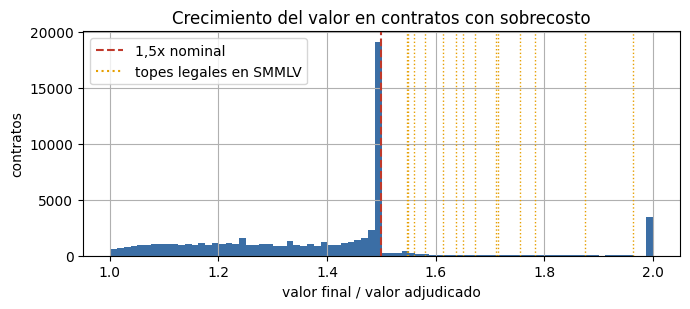

Escenario nominal : se descartan 6,262 registros -> quedan 243,338 | tasa de sobrecosto 24.9%
Escenario legal   : se descartan 4,306 registros -> quedan 245,294 | tasa de sobrecosto 25.5%

Contratos que el corte nominal descartaba y el legal conserva: 1,956 (crecimiento mediano 1.555)

Escenario principal: legal · 245,294 contratos · tasa 25.5%


,tasa,contratos
anio_firma,,
2021,0.239,50940
2022,0.260,60974
2023,0.264,65157
2024,0.255,68223


In [99]:
crecimiento = df.valor_final / df.valor_adjudicado
df["crecimiento"] = crecimiento
print(f"Tasa de sobrecosto antes del corte: {df.sobrecosto.mean():.1%}  ({df.sobrecosto.sum():,} de {len(df):,})")
print("\nCrecimiento (valor final / adjudicado) en contratos con sobrecosto:")
print(crecimiento[df.sobrecosto == 1].describe(percentiles=[.1, .5, .9, .99]).round(3))

# año de la última modificación (adiciones) para los contratos donde el tope importa
candidatos = df.loc[crecimiento > 1.5001, "id_contrato"]
mods = descargar_por_ids(ADICIONES, "id_contrato", candidatos, ["id_contrato", "tipo", "fecharegistro"])
tipo = mods.tipo.fillna("").str.lower()
mods = mods[tipo.str.contains("valor") | tipo.str.contains("modificacion general")]
anio_mod = pd.to_datetime(mods.fecharegistro, errors="coerce").dt.year.groupby(mods.id_contrato).max()

anio_ultima = df.id_contrato.map(anio_mod)
df["fuente_tope"] = np.where(anio_ultima.notna(), "adiciones", "fecha de fin")
anio_ultima = anio_ultima.fillna(df.fecha_fin.dt.year)
anio_ultima = np.maximum(anio_ultima.clip(upper=max(SMMLV)), df.anio_firma).astype(int)
df["tope_legal"] = 1 + 0.5 * anio_ultima.map(SMMLV) / df.anio_firma.map(SMMLV)
es_especial = df.modalidad_de_contratacion.str.contains("régimen especial", case=False, na=False)

print(f"\nContratos con crecimiento > 1,5x: {len(candidatos):,} · año tomado de adiciones: "
      f"{(df.loc[crecimiento > 1.5001, 'fuente_tope'] == 'adiciones').mean():.1%}, del resto: fecha de fin")

viola = {
    "nominal": np.asarray(crecimiento > 1.5001),
    "legal": np.where(es_especial, crecimiento > TOPE_ERROR, crecimiento > df.tope_legal + 1e-4),
}
fig, ax = plt.subplots(figsize=(7, 3.2))
crecimiento[df.sobrecosto == 1].clip(upper=2).hist(bins=80, ax=ax, color="#3b6ea5")
ax.axvline(1.5, color="#c0392b", ls="--", label="1,5x nominal")
for t in sorted(df.loc[crecimiento > 1.5001, "tope_legal"].round(3).unique()):
    if 1.5001 < t <= 2:
        ax.axvline(t, color="#e69f00", ls=":", lw=1)
ax.plot([], [], color="#e69f00", ls=":", label="topes legales en SMMLV")
ax.set(title="Crecimiento del valor en contratos con sobrecosto",
       xlabel="valor final / valor adjudicado", ylabel="contratos")
ax.legend(); plt.tight_layout(); plt.show()

ESCENARIOS = {}
for nombre, v in viola.items():
    d = df[~v].reset_index(drop=True)
    ESCENARIOS[nombre] = d
    print(f"Escenario {nombre:8s}: se descartan {int(v.sum()):,} registros -> quedan {len(d):,} "
          f"| tasa de sobrecosto {d.sobrecosto.mean():.1%}")

recuperados = (~viola["legal"]) & viola["nominal"]
print(f"\nContratos que el corte nominal descartaba y el legal conserva: {recuperados.sum():,} "
      f"(crecimiento mediano {crecimiento[recuperados].median():.3f})")

df = ESCENARIOS[CORTE_PRINCIPAL].copy()
print(f"\nEscenario principal: {CORTE_PRINCIPAL} · {len(df):,} contratos · tasa {df.sobrecosto.mean():.1%}")
display(df.groupby("anio_firma").sobrecosto.agg(tasa="mean", contratos="size").round(3))

In [101]:
print("Tasa de sobrecosto por modalidad:")
display(df.groupby("modalidad_de_contratacion").sobrecosto.agg(tasa="mean", contratos="size")
          .sort_values("contratos", ascending=False).round(3))

Tasa de sobrecosto por modalidad:


,tasa,contratos
modalidad_de_contratacion,,
Mínima cuantía,0.202,141350
Contratación Directa (con ofertas),0.248,29031
Selección Abreviada de Menor Cuantía,0.394,25496
Selección abreviada subasta inversa,0.311,17251
Contratación régimen especial (con ofertas),0.258,17245
Concurso de méritos abierto,0.322,5691
Licitación pública,0.574,4931
Licitación pública Obra Publica,0.553,3609
Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes,0.528,532


### 4.3 Validación del objetivo con el conjunto de adiciones

Si `valor_del_contrato` incluye las adiciones, los contratos marcados con sobrecosto deberían tener modificaciones registradas, y los demás casi nunca. Se toman 300 contratos de cada clase y se buscan sus registros en *SECOP II - Adiciones*.

Ese conjunto **no trae montos** y clasifica los registros de forma irregular: muchas adiciones de valor quedan como «Modificación general» o «No definido». Por eso la tabla muestra, para **cada tipo**, qué porcentaje de contratos de cada clase tiene al menos un registro. La lectura útil es la comparación entre clases: un tipo que aparece mucho más en los contratos con sobrecosto que en los demás está capturando adiciones.

In [102]:
muestra = pd.concat([df[df.sobrecosto == 1].sample(min(300, int(df.sobrecosto.sum())), random_state=SEMILLA),
                     df[df.sobrecosto == 0].sample(300, random_state=SEMILLA)])
adiciones = descargar_por_ids(ADICIONES, "id_contrato", muestra.id_contrato.tolist())
print("Columnas de SECOP II - Adiciones:", adiciones.columns.tolist())

presencia = (pd.crosstab(adiciones.id_contrato, adiciones.tipo) > 0).reindex(muestra.id_contrato, fill_value=False)
presencia["valor o modificación general"] = presencia[[c for c in presencia.columns
                                                       if "valor" in c.lower() or "modificacion general" in c.lower()]].any(axis=1)
presencia["cualquier registro"] = presencia.any(axis=1)
por_clase = presencia.groupby(muestra.set_index("id_contrato").sobrecosto).mean().T
por_clase.columns = ["% sin sobrecosto", "% con sobrecosto"]
display((100 * por_clase).round(1).sort_values("% con sobrecosto", ascending=False))
print("Lectura: los tipos con un porcentaje alto en 'con sobrecosto' y bajo en 'sin sobrecosto' confirman la etiqueta.")

  cb9c-h8sn: 600 llaves consultadas -> 1,555 filas
Columnas de SECOP II - Adiciones: ['identificador', 'id_contrato', 'tipo', 'descripcion', 'fecharegistro']


,% sin sobrecosto,% con sobrecosto
tipo,,
cualquier registro,73.3,100.0
valor o modificación general,30.0,99.7
Modificacion General,29.3,86.0
No definido,55.7,56.3
Adicion en el valor,1.3,34.3
Conclusion,25.0,24.0
Reactivación,4.3,9.0
Suspensión,3.7,8.7
Cesion,0.0,0.7


Lectura: los tipos con un porcentaje alto en 'con sobrecosto' y bajo en 'sin sobrecosto' confirman la etiqueta.


### 4.4 Validación de `liquidaci_n` y de las demás cláusulas del contrato

Una columna que se fija **al firmar** debe tener una distribución parecida en contratos recién firmados y en los contratos del período. Una que se actualiza durante la ejecución, no: en los contratos nuevos todavía no ha cambiado. Se comparan ambas distribuciones con la **distancia de variación total** (0 = idénticas, 1 = sin nada en común). `estado_contrato` sirve de **control positivo**: se actualiza con seguridad, así que su distancia debe ser grande.

Regla: una cláusula con distancia mayor a 0,10 se trata como sospechosa y se excluye del modelo. Es una regla conservadora: una diferencia también puede venir de cambios en las prácticas de contratación entre años. La **dirección** ayuda a distinguirlas: si la cláusula se llenara al liquidar, los contratos viejos tendrían más «Si» que los nuevos.

In [ ]:
CLAUSULAS = ["liquidaci_n", "obligaci_n_ambiental", "reversion", "el_contrato_puede_ser_prorrogado",
             "habilita_pago_adelantado", "documentos_tipo", "espostconflicto"]
desde = (FECHA_DESCARGA - pd.Timedelta(days=90)).strftime("%Y-%m-%d")
recientes = descargar(
    CONTRATOS, f"fecha_de_firma >= '{desde}' and modalidad_de_contratacion not in {SIN_OFERTAS}",
    CLAUSULAS + ["estado_contrato", "fecha_de_firma"], max_filas=20_000)

def variacion_total(a, b):
    pa = a.fillna("NA").value_counts(normalize=True)
    pb = b.fillna("NA").value_counts(normalize=True)
    return 0.5 * pa.subtract(pb, fill_value=0).abs().sum()

deriva = pd.DataFrame({
    "distancia": {c: variacion_total(df[c], recientes[c]) for c in CLAUSULAS + ["estado_contrato"]},
    "% 'Si' en el período": {c: (df[c] == "Si").mean() for c in CLAUSULAS},
    "% 'Si' recientes": {c: (recientes[c] == "Si").mean() for c in CLAUSULAS},
}).round(3)
display(deriva.sort_values("distancia", ascending=False))

if deriva.loc["estado_contrato", "distancia"] < 0.2:
    print("Aviso: el control positivo cambió poco; la prueba es poco informativa con esta muestra.")
EXCLUIR_POR_DERIVA = [c for c in CLAUSULAS if deriva.loc[c, "distancia"] > 0.10]
print(f"Cláusulas excluidas por sospecha de actualizarse después de firmar: {EXCLUIR_POR_DERIVA or 'ninguna'}")

print("\nTasa de sobrecosto según liquidaci_n:")
display(df.groupby("liquidaci_n").sobrecosto.agg(tasa="mean", contratos="size").round(3))
print("Distribución de liquidaci_n según estado_contrato (filas = estado):")
display(pd.crosstab(df.estado_contrato, df.liquidaci_n, normalize="index").round(3))

### 4.5 Las modalidades sin ofertas y la cobertura del modelo

*Contratación directa* y *Contratación régimen especial* sin ofertas son la mayoría de los contratos del SECOP II. No hay una razón metodológica para excluirlas del objetivo «predecir sobrecostos en cualquier contrato», pero hay una razón **de datos**: el objetivo necesita un valor adjudicado, y en estas modalidades no hay adjudicación registrada en *Procesos*. Esta celda lo mide con una muestra pseudoaleatoria (procesos cuya llave termina en `00`, cerca del 1 %) y calcula qué parte de los contratos del período cubre el modelo.

**Consecuencia para el proyecto:** el modelo responde la pregunta solo para las modalidades competitivas y las variantes «con ofertas». Extenderlo a la contratación directa exigiría otro valor inicial de referencia (por ejemplo, el precio base del proceso, si se valida que coincide con el valor inicial del contrato), porque el conjunto de adiciones no trae montos.

In [104]:
conteo = pd.DataFrame(_get(API.format(CONTRATOS).replace(".csv", ".json"), {
    "$select": "modalidad_de_contratacion, count(*) as contratos",
    "$where": f"fecha_de_firma between '{DESDE}' and '{HASTA}'",
    "$group": "modalidad_de_contratacion", "$order": "contratos DESC"}).json())
conteo["contratos"] = num(conteo["contratos"])
conteo["% del total"] = (100 * conteo.contratos / conteo.contratos.sum()).round(1)
print(f"Contratos firmados entre {min(ANIOS)} y {max(ANIOS)} por modalidad (todas):")
display(conteo)

es_sin_ofertas = conteo.modalidad_de_contratacion.isin(["Contratación directa", "Contratación régimen especial"])
COBERTURA = conteo.loc[~es_sin_ofertas, "contratos"].sum() / conteo.contratos.sum()
print(f"\n>>> El modelo cubre las modalidades que suman el {COBERTURA:.1%} de los contratos del período; "
      f"el {1 - COBERTURA:.1%} restante (sin ofertas) queda por fuera.")

so = descargar(
    CONTRATOS,
    f"fecha_de_firma between '{DESDE}' and '{HASTA}' "
    f"and modalidad_de_contratacion in {SIN_OFERTAS} and proceso_de_compra like '%00'",
    ["proceso_de_compra", "id_contrato", "modalidad_de_contratacion", "valor_del_contrato", "tipo_de_contrato"],
    max_filas=3_000)
proc_so = descargar_por_ids(PROCESOS, "id_del_portafolio", so.proceso_de_compra,
                            ["id_del_portafolio", "adjudicado", "valor_total_adjudicacion", "precio_base"])
proc_so = proc_so.drop_duplicates("id_del_portafolio", keep="last")
diag = so.merge(proc_so, left_on="proceso_de_compra", right_on="id_del_portafolio", how="left")
diag["tiene_proceso"] = diag.id_del_portafolio.notna()
diag["tiene_adjudicado"] = num(diag.valor_total_adjudicacion) > 0
diag["tiene_precio_base"] = num(diag.precio_base) > 0

resumen_so = diag.groupby("modalidad_de_contratacion").agg(
    contratos=("id_contrato", "size"), con_proceso=("tiene_proceso", "mean"),
    con_valor_adjudicado=("tiene_adjudicado", "mean"), con_precio_base=("tiene_precio_base", "mean"))
display(resumen_so.round(3))
print("Tipo de contrato en la muestra:")
display(so.tipo_de_contrato.value_counts(normalize=True).head(6).round(3))

Contratos firmados entre 2021 y 2024 por modalidad (todas):


,modalidad_de_contratacion,contratos,% del total
0,Contratación directa,2325140,77.9
1,Contratación régimen especial,375787,12.6
2,Mínima cuantía,153170,5.1
3,Contratación Directa (con ofertas),32244,1.1
4,Selección Abreviada de Menor Cuantía,29112,1.0
5,Selección abreviada subasta inversa,24608,0.8
6,Contratación régimen especial (con ofertas),23386,0.8
7,Concurso de méritos abierto,7945,0.3
8,Licitación pública,7683,0.3
9,Licitación pública Obra Publica,4875,0.2



>>> El modelo cubre las modalidades que suman el 9.5% de los contratos del período; el 90.5% restante (sin ofertas) queda por fuera.
  jbjy-vk9h: offset=      0  filas=3,000
  p6dx-8zbt: 2,839 llaves consultadas -> 2,858 filas


,contratos,con_proceso,con_valor_adjudicado,con_precio_base
modalidad_de_contratacion,,,,
Contratación directa,2626,0.999,0.0,0.990
Contratación régimen especial,374,1.000,0.0,0.997


Tipo de contrato en la muestra:


tipo_de_contrato
Prestación de servicios       0.917
Decreto 092 de 2017           0.035
Otro                          0.023
Arrendamiento de inmuebles    0.012
Suministros                   0.005
Obra                          0.004
Name: proportion, dtype: float64

## 5. Selección de variables: identificadores y fuga de información

### 5.1 Columnas excluidas

**Identificadores** (únicos por registro o por entidad/persona; no generalizan y permiten memorizar):
`id_contrato`, `referencia_del_contrato`, `proceso_de_compra`, `id_del_proceso`, `id_del_portafolio`, `referencia_del_proceso`, `id_adjudicacion`, `urlproceso`, `nit_entidad`, `codigo_entidad`, `nombre_entidad`, `documento_proveedor`, `codigo_proveedor`, `proveedor_adjudicado`, `nit_del_proveedor_adjudicado`, nombres y documentos de representante legal / supervisor / ordenadores, `c_digo_bpin`, datos bancarios.

**Fuga de información** (se conocen o se actualizan *después* de adjudicar):

| Columna | Por qué hay fuga |
|---|---|
| `valor_del_contrato` | incluye las adiciones: **es** el objetivo |
| `presupuesto_general_de_la_nacion_pgn`, `sistema_general_de_participaciones`, `sistema_general_de_regal_as`, `recursos_propios*`, `recursos_de_credito` | suman el valor **final** del contrato (se verifica abajo) |
| `fecha_de_fin_del_contrato`, `duraci_n_del_contrato` | se mueven con las prórrogas (se verifica abajo); `fecha_de_fin_del_contrato` solo se usa para filtrar contratos terminados (4.1) y como cota del tope legal (4.2) |
| `estado_contrato` | «Modificado» delata la adición |
| `dias_adicionados`, `fecha_de_notificaci_n_de_prorrogaci_n` | prórrogas posteriores |
| `valor_facturado`, `valor_pagado`, `valor_pendiente_*`, `valor_amortizado`, `saldo_cdp`, `saldo_vigencia` | ejecución financiera |
| `estado_del_procedimiento`, `estado_resumen`, `fase`, `ultima_actualizacion`, fechas de liquidación | estados posteriores |
| cláusulas en `EXCLUIR_POR_DERIVA` | cambian entre contratos nuevos y viejos (sección 4.4) |

**Texto libre** (`objeto_del_contrato`, `descripcion_del_proceso`): no se usa en este ejercicio. Un análisis previo mostró que el objeto y la descripción coinciden en la mayoría de los contratos, que el texto repite en buena parte la información de la categoría UNSPSC, que incluye siglas y programas propios de una sola entidad (así que funcionaría como un identificador de la entidad) y que algunos registros se editan después de firmar («se realizó otrosí»). Queda como trabajo futuro.

In [105]:
fuentes = sum(num(df[c]).fillna(0) for c in ["presupuesto_general_de_la_nacion_pgn", "recursos_propios"])
dur_fechas = (pd.to_datetime(df.fecha_de_fin_del_contrato, errors="coerce")
              - pd.to_datetime(df.fecha_de_inicio_del_contrato, errors="coerce")).dt.days

print("Sobrecosto según estado_contrato (fuga evidente):")
display(df.groupby("estado_contrato").sobrecosto.mean().round(3).to_frame("tasa de sobrecosto"))
print("Duración mediana según fechas del contrato (días):")
display(dur_fechas.groupby(df.sobrecosto).median().rename({0: "sin sobrecosto", 1: "con sobrecosto"}))
print(f"dias_adicionados > 0: tasa de sobrecosto {df.sobrecosto[num(df.dias_adicionados) > 0].mean():.1%} "
      f"vs {df.sobrecosto[~(num(df.dias_adicionados) > 0)].mean():.1%}")

Sobrecosto según estado_contrato (fuga evidente):


,tasa de sobrecosto
estado_contrato,
Aprobado,0.003
Cerrado,0.220
En ejecución,0.009
Modificado,0.577
Suspendido,0.253
cedido,0.068
terminado,0.285


Duración mediana según fechas del contrato (días):


sobrecosto
sin sobrecosto     66.0
con sobrecosto    202.0
dtype: float64

dias_adicionados > 0: tasa de sobrecosto 53.1% vs 22.1%


### 5.2 Variables del modelo (disponibles al adjudicar)

* **Entidad:** departamento, orden, sector, rama, centralizada/descentralizada.
* **Contrato y proceso:** tipo de contrato, modalidad, categoría UNSPSC (segmento y familia), origen de recursos, destino del gasto, cláusulas validadas en la sección 4.4, mes de firma.
* **Montos:** log del precio base, log del valor adjudicado y **descuento** (adjudicado / precio base).
* **Duración pactada** en días (del proceso, no de las fechas del contrato).
* **Competencia:** número de lotes, proveedores invitados, respuestas recibidas, proveedores únicos que respondieron.
* **Proveedor:** pyme, grupo/consorcio, tipo de documento.

In [106]:
CAT_CONTRATO = ["departamento", "orden", "sector", "rama", "entidad_centralizada", "tipo_de_contrato",
                "modalidad_de_contratacion", "origen_de_los_recursos", "destino_gasto", "es_pyme",
                "es_grupo", "tipodocproveedor"] + [c for c in CLAUSULAS if c not in EXCLUIR_POR_DERIVA]
CATEGORICAS = CAT_CONTRATO + ["unspsc_segmento", "unspsc_familia"]
NUMERICAS = ["log_precio_base", "log_valor_adjudicado", "adjudicado_sobre_base", "duracion_dias",
             "numero_de_lotes", "proveedores_invitados", "proveedores_con_invitacion",
             "respuestas_al_procedimiento", "proveedores_unicos_con", "mes_firma"]
DIAS = {"día(s)": 1, "Dia(s)": 1, "Semana(s)": 7, "Mes(es)": 30, "Año(s)": 365, "Hora(s)": 1 / 24}

def construir_X(d):
    X = d[CAT_CONTRATO].astype(str).copy()
    unspsc = d.codigo_de_categoria_principal.str.extract(r"V1\.(\d{8})")[0]
    X["unspsc_segmento"] = unspsc.str[:2].fillna("NA")
    X["unspsc_familia"] = unspsc.str[:4].fillna("NA")
    X["log_precio_base"] = np.log1p(d.precio_base_n)
    X["log_valor_adjudicado"] = np.log1p(d.valor_adjudicado)
    X["adjudicado_sobre_base"] = d.valor_adjudicado / d.precio_base_n
    X["duracion_dias"] = num(d.duracion) * d.unidad_de_duracion.map(DIAS)
    for c in ["numero_de_lotes", "proveedores_invitados", "proveedores_con_invitacion",
              "respuestas_al_procedimiento", "proveedores_unicos_con"]:
        X[c] = num(d[c])
    X["mes_firma"] = pd.to_datetime(d.fecha_de_firma, errors="coerce").dt.month
    return X[CATEGORICAS + NUMERICAS]

X = construir_X(df)
y = df.sobrecosto.values
grupos = df.nit_entidad.values   # solo para separar por entidad
print(X.shape, "·", len(CATEGORICAS), "categóricas ·", len(NUMERICAS), "numéricas")
X.head()

(245294, 30) · 20 categóricas · 10 numéricas


,departamento,orden,sector,rama,entidad_centralizada,tipo_de_contrato,modalidad_de_contratacion,origen_de_los_recursos,destino_gasto,es_pyme,es_grupo,tipodocproveedor,obligaci_n_ambiental,reversion,el_contrato_puede_ser_prorrogado,habilita_pago_adelantado,documentos_tipo,espostconflicto,unspsc_segmento,unspsc_familia,log_precio_base,log_valor_adjudicado,adjudicado_sobre_base,duracion_dias,numero_de_lotes,proveedores_invitados,proveedores_con_invitacion,respuestas_al_procedimiento,proveedores_unicos_con,mes_firma
0,Distrito Capital de Bogotá,Nacional,Cultura,Ejecutivo,Centralizada,Prestación de servicios,Mínima cuantía,Distribuido,Inversión,Si,No,NIT,No,No,No,No,No definido,No,72,7215,15.607270,15.607270,1.000000,210.0,0,0,0,2,2,4
1,Cesar,Territorial,Servicio Público,Ejecutivo,Descentralizada,Compraventa,Mínima cuantía,Distribuido,Funcionamiento,Si,No,NIT,No,No,No,No,No,No,43,4323,17.901235,17.891182,0.989997,10.0,0,0,0,0,0,12
2,No Definido,Territorial,agricultura,Corporación Autónoma,Centralizada,Decreto 092 de 2017,Contratación régimen especial (con ofertas),Recursos Propios,Inversión,Si,No,NIT,No,No,No,No,No,No,60,6010,19.257928,19.257928,1.000000,120.0,0,0,0,1,1,8
3,Tolima,Territorial,Servicio Público,Ejecutivo,Centralizada,Compraventa,Mínima cuantía,Distribuido,Funcionamiento,Si,No,NIT,No,No,No,No,No,No,95,9513,16.810993,16.808038,0.997049,3.0,0,0,0,3,3,12
4,Cundinamarca,Nacional,Ley de Justicia,Corporación Autónoma,Centralizada,Suministros,Mínima cuantía,Distribuido,Funcionamiento,Si,No,Cédula de Ciudadanía,No,No,No,No,No,No,82,8210,16.118096,16.118096,1.000000,270.0,0,0,0,5,5,3


### 5.3 Datos faltantes en las variables del modelo

Antes de decidir cómo tratar los faltantes hay que ver cuántos hay, dónde están y si dicen algo del sobrecosto. La tabla muestra, para cada variable del modelo:

* **% faltante** en entrenamiento (2021-2023) y en prueba (2024). En las categóricas cuenta como faltante el valor vacío (`NaN`, que `construir_X` convierte en el texto `"nan"`, o `"NA"` en UNSPSC) y, aparte, los **marcadores** que SECOP usa en lugar de un dato («No Definido» y similares).
* **Tasa de sobrecosto con y sin faltante**, solo en entrenamiento. Si difieren, el faltante es **informativo**: no ocurre al azar y conviene que el modelo lo vea.
* **Tratamiento actual** y una **sugerencia** según una regla simple:

| Situación | Sugerencia |
|---|---|
| sin faltantes | ninguno |
| más del 40 % faltante | evaluar excluir la variable (o usar solo un indicador de faltante) |
| el % faltante cambia 10 puntos o más entre entrenamiento y prueba | revisar la fuente: el registro cambió entre años |
| la tasa de sobrecosto difiere 5 puntos o más (con al menos 100 faltantes) | imputar **y** agregar un indicador de faltante |
| resto | imputación simple (mediana o categoría propia) |

La regla usa solo los faltantes; los marcadores ya funcionan como una categoría más, aunque conviene saber cuántos hay. La sugerencia es una guía para decidir; esta sección **no cambia** el tratamiento. Para agregar indicadores en los modelos lineales bastaría `SimpleImputer(strategy="median", add_indicator=True)` en `prep_lineal`; el boosting ya aprende una dirección propia para los faltantes en cada corte.

,tipo,% faltante entren.,% faltante prueba,% marcador entren.,n faltantes entren.,tasa con faltante,tasa sin faltante,tratamiento actual,Δ tasa (pp),sugerencia
variable,,,,,,,,,,
unspsc_segmento,categórica,3.55,10.09,0.00,6284,0.308,0.253,categoría propia (one-hot / ordinal / nativa),5.4,imputar + indicador de faltante
unspsc_familia,categórica,3.55,10.09,0.00,6284,0.308,0.253,categoría propia (one-hot / ordinal / nativa),5.4,imputar + indicador de faltante
documentos_tipo,categórica,0.00,0.00,4.86,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
departamento,categórica,0.00,0.00,3.08,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
habilita_pago_adelantado,categórica,0.00,0.00,2.33,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
tipodocproveedor,categórica,0.00,0.00,1.22,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
destino_gasto,categórica,0.00,0.00,0.19,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
orden,categórica,0.00,0.00,0.00,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno
sector,categórica,0.00,0.00,0.00,0,NaN,0.255,categoría propia (one-hot / ordinal / nativa),NaN,ninguno


Variables con algún faltante: 3 de 30
Sugerencias: {'ninguno': 27, 'imputar + indicador de faltante': 2, 'imputación simple': 1}


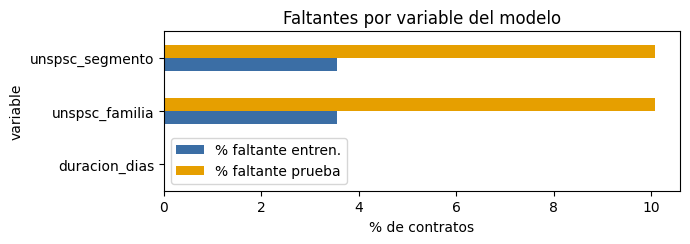

In [107]:
VACIO = {"", "nan", "none", "null", "na", "n/a"}
MARCADOR = {"no definido", "no definida", "sin definir", "no aplica", "sin descripcion", "sin descripción"}
anio = df.anio_firma.values
en_tr, en_te = np.isin(anio, ANIOS_ENTRENAMIENTO), anio == ANIO_PRUEBA

def pct(m):
    return 100 * m.mean() if len(m) else np.nan

filas = []
for c in CATEGORICAS + NUMERICAS:
    if c in CATEGORICAS:
        texto = X[c].astype(object).where(X[c].notna(), "nan").astype(str).str.strip().str.lower()   # NaN como texto en cualquier versión de pandas
        falta, marca = texto.isin(VACIO).values, texto.isin(MARCADOR).values
        actual = "categoría propia (one-hot / ordinal / nativa)"
    else:
        v = X[c].astype(float)
        falta, marca = (~np.isfinite(v)).values, np.zeros(len(v), bool)
        actual = "mediana (lineal y árboles) · nativo (boosting)"
    ft = falta[en_tr]
    yt = y[en_tr]
    filas.append({"variable": c, "tipo": "categórica" if c in CATEGORICAS else "numérica",
                  "% faltante entren.": pct(ft), "% faltante prueba": pct(falta[en_te]),
                  "% marcador entren.": pct(marca[en_tr]) if c in CATEGORICAS else np.nan,
                  "n faltantes entren.": int(ft.sum()),
                  "tasa con faltante": yt[ft].mean() if ft.any() else np.nan,
                  "tasa sin faltante": yt[~ft].mean() if (~ft).any() else np.nan,
                  "tratamiento actual": actual})
faltantes = pd.DataFrame(filas).set_index("variable")
faltantes["Δ tasa (pp)"] = 100 * (faltantes["tasa con faltante"] - faltantes["tasa sin faltante"])

def sugerencia(r):
    p = max(r["% faltante entren."], r["% faltante prueba"])
    if p == 0:
        return "ninguno"
    if p > 40:
        return "evaluar excluir (o solo indicador)"
    if abs(r["% faltante prueba"] - r["% faltante entren."]) >= 10:
        return "revisar fuente: cambia entre años"
    if abs(r["Δ tasa (pp)"]) >= 5 and r["n faltantes entren."] >= 100:
        return "imputar + indicador de faltante"
    return "imputación simple"

faltantes["sugerencia"] = faltantes.apply(sugerencia, axis=1)
faltantes = faltantes.sort_values(["% faltante entren.", "% marcador entren."], ascending=False)
display(faltantes.round({"% faltante entren.": 2, "% faltante prueba": 2, "% marcador entren.": 2,
                         "tasa con faltante": 3, "tasa sin faltante": 3, "Δ tasa (pp)": 1}))

con_falta = faltantes[(faltantes["% faltante entren."] > 0) | (faltantes["% faltante prueba"] > 0)]
print(f"Variables con algún faltante: {len(con_falta)} de {len(faltantes)}")
print("Sugerencias:", faltantes.sugerencia.value_counts().to_dict())
if len(con_falta):
    ax = con_falta[["% faltante entren.", "% faltante prueba"]].iloc[::-1].plot.barh(
        figsize=(7, 0.35 * len(con_falta) + 1.5), color=["#3b6ea5", "#e69f00"])
    ax.set(xlabel="% de contratos", title="Faltantes por variable del modelo")
    plt.tight_layout(); plt.show()

In [108]:
# de dónde vienen los faltantes numéricos: valores que no se pudieron leer y unidades de duración sin equivalencia
fuente = {"duracion_dias": "duracion", "numero_de_lotes": "numero_de_lotes",
          "proveedores_invitados": "proveedores_invitados", "proveedores_con_invitacion": "proveedores_con_invitacion",
          "respuestas_al_procedimiento": "respuestas_al_procedimiento", "proveedores_unicos_con": "proveedores_unicos_con",
          "mes_firma": "fecha_de_firma"}
origen = pd.DataFrame({v: {"vacío en la fuente": int(df[col].isna().sum()),
                           "no interpretable": int((df[col].notna() & (num(df[col]) if v != "mes_firma"
                                                   else pd.to_datetime(df[col], errors="coerce")).isna()).sum())}
                       for v, col in fuente.items()}).T
sin_unidad = ~df.unidad_de_duracion.isin(list(DIAS))
origen.loc["duracion_dias", "unidad sin equivalencia"] = int(sin_unidad.sum())
display(origen.fillna(0).astype(int))
if sin_unidad.any():
    print("Unidades de duración que no están en DIAS:", df.unidad_de_duracion[sin_unidad].value_counts(dropna=False).head(10).to_dict())

,vacío en la fuente,no interpretable,unidad sin equivalencia
duracion_dias,0,0,3
numero_de_lotes,0,0,0
proveedores_invitados,0,0,0
proveedores_con_invitacion,0,0,0
respuestas_al_procedimiento,0,0,0
proveedores_unicos_con,0,0,0
mes_firma,0,0,0


Unidades de duración que no están en DIAS: {'No Especificado': 3}


#### Verificaciones puntuales

**UNSPSC sin código.** El faltante de la categoría UNSPSC no es un error de lectura: la fuente trae el texto `UNSPECIFIED`. Casi no aparece en 2021-2022 y sube desde 2023, así que es un **cambio en la forma de registrar** los contratos. Se mantiene como una categoría propia (`"NA"`): el entrenamiento incluye 2023, así que el modelo ve suficientes casos, y la segunda ventana temporal (sección 12.2), que entrena casi sin ellos, conserva el desempeño.

**Duración del proceso.** *Procesos* es una foto del estado actual del proceso, no su historial. Si las entidades actualizaran la duración del proceso al prorrogar el contrato, `duracion_dias` tendría fuga. Se compara con la duración final del contrato (por fechas, que sí incluye prórrogas): si la variable es la duración **pactada**, en los contratos con sobrecosto (que suelen prorrogarse) debe coincidir menos con la final y la razón pactada/final debe ser menor que 1.

In [ ]:
cod = df.codigo_de_categoria_principal
no_leido = cod.str.extract(r"V1\.(\d{8})")[0].isna()
print("UNSPSC sin código por año de firma:")
display(no_leido.groupby(df.anio_firma).mean().round(3).to_frame("% sin código"))
print("Valores sin código en la fuente:", cod[no_leido].value_counts(dropna=False).head(5).to_dict())
ap_unspsc = df.sobrecosto[no_leido & en_tr].mean(), df.sobrecosto[~no_leido & en_tr].mean()
print(f"Tasa de sobrecosto en entrenamiento: sin código {ap_unspsc[0]:.3f} · con código {ap_unspsc[1]:.3f}")

igual = (X.duracion_dias - dur_fechas).abs() <= 5
razon = X.duracion_dias / dur_fechas.replace(0, np.nan)
chequeo_dur = pd.DataFrame({"duración pactada ≈ final (±5 días)": igual.groupby(df.sobrecosto).mean(),
                            "mediana pactada / final": razon.groupby(df.sobrecosto).median()}
                           ).rename(index={0: "sin sobrecosto", 1: "con sobrecosto"}).round(3)
display(chequeo_dur)
sin_fuga = (chequeo_dur.iloc[1, 0] < chequeo_dur.iloc[0, 0]) and (chequeo_dur.iloc[1, 1] < 1)
print("duracion_dias:", "se comporta como duración pactada (sin evidencia de fuga)" if sin_fuga
      else "ADVERTENCIA: coincide con la duración final también en contratos con sobrecosto; revisar fuga")

## 6. Partición temporal y validación cruzada agrupada por entidad

* **Entrenamiento:** contratos firmados entre 2021 y 2023 (`ANIOS_ENTRENAMIENTO`).
* **Prueba:** contratos firmados en 2024 (`ANIO_PRUEBA`). Simula el uso real: el modelo se construye con el pasado y se aplica a contratos nuevos. Se usa **una sola vez**, en la sección 10. Incluye entidades que ya contrataban antes y entidades nuevas; la sección 10 reporta ambas por separado.
* **Validación cruzada** dentro de entrenamiento (`GroupKFold`, `N_PLIEGUES` pliegues, **por entidad**): elige hiperparámetros, el número de iteraciones del boosting, las épocas de la red y el **umbral** de cada modelo, con predicciones fuera de pliegue. Una misma entidad contrata de forma parecida; si sus contratos quedaran a ambos lados de un pliegue, el modelo la «reconocería» y la validación sería optimista.

La parada temprana interna de `HistGradientBoostingClassifier` y de `MLPClassifier` separa la validación **por filas**, mezclando contratos de una misma entidad. Por eso se desactiva y el número de iteraciones o épocas se elige con estos mismos pliegues por entidad.

In [109]:
anios = df.anio_firma.values
tr = np.where(np.isin(anios, ANIOS_ENTRENAMIENTO))[0]
te = np.where(anios == ANIO_PRUEBA)[0]
X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y[tr], y[te]
g_tr, g_te = grupos[tr], grupos[te]
ENTIDAD_NUEVA = ~np.isin(g_te, g_tr)      # entidades de prueba que no aparecen en entrenamiento
print(f"Entrenamiento {ANIOS_ENTRENAMIENTO}: {len(tr):,} contratos, {len(set(g_tr)):,} entidades | tasa {y_tr.mean():.1%}")
print(f"Prueba {ANIO_PRUEBA}:            {len(te):,} contratos, {len(set(g_te)):,} entidades | tasa {y_te.mean():.1%}")
print(f"  de la prueba, contratos de entidades nuevas: {ENTIDAD_NUEVA.sum():,} ({ENTIDAD_NUEVA.mean():.1%})")

PLIEGUES = list(GroupKFold(n_splits=N_PLIEGUES).split(X_tr, y_tr, g_tr))
for k, (a, v) in enumerate(PLIEGUES, 1):
    assert not set(g_tr[a]) & set(g_tr[v])
    print(f"  pliegue {k}: validación {len(v):,} contratos, {len(set(g_tr[v])):,} entidades, tasa {y_tr[v].mean():.1%}")

Entrenamiento [2021, 2022, 2023]: 177,071 contratos, 2,547 entidades | tasa 25.5%
Prueba 2024:            68,223 contratos, 2,322 entidades | tasa 25.5%
  de la prueba, contratos de entidades nuevas: 1,897 (2.8%)
  pliegue 1: validación 35,415 contratos, 501 entidades, tasa 24.0%
  pliegue 2: validación 35,414 contratos, 510 entidades, tasa 26.9%
  pliegue 3: validación 35,414 contratos, 512 entidades, tasa 26.4%
  pliegue 4: validación 35,414 contratos, 512 entidades, tasa 25.3%
  pliegue 5: validación 35,414 contratos, 512 entidades, tasa 25.0%


## 7. Marco de evaluación

**Métrica para elegir modelos e hiperparámetros:** PR-AUC (precisión promedio), media de los pliegues por entidad. Con 25 % de positivos, un clasificador al azar tiene PR-AUC igual a la tasa de positivos; el ROC-AUC se reporta como complemento.

**Regla del umbral (igual para todos los modelos):** el umbral que maximiza **F-beta** en las predicciones **fuera de pliegue** del entrenamiento. Con `BETA = 1` es el F1; con `BETA = 2`, la exhaustividad pesa el doble, útil si a una contraloría le cuesta más dejar pasar un sobrecosto que revisar un contrato de más. El umbral nunca se elige con la prueba ni con predicciones del propio entrenamiento.

**Incertidumbre:** bootstrap **por entidad** sobre la prueba (contratos de 2024): se remuestrean entidades completas, no filas, porque los contratos de una entidad no son independientes.

**Preprocesamiento** (ajustado siempre dentro de cada pliegue):

* *lineal* (logística y red): one-hot de categorías con al menos 30 casos, mediana para faltantes y estandarización.
* *árboles* (árbol y bosque): códigos ordinales de categoría y mediana para faltantes; los árboles no necesitan escalar.
* *boosting*: categorías nativas de `HistGradientBoostingClassifier`.

In [110]:
prep_lineal = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30), CATEGORICAS),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), NUMERICAS),
])
prep_arbol = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                           encoded_missing_value=-2), CATEGORICAS),
    ("num", SimpleImputer(strategy="median"), NUMERICAS),
])

# niveles para el boosting, aprendidos SOLO en entrenamiento (máx. 250 por columna); lo demás -> "OTRA"
NIVELES = {c: X_tr[c].value_counts().index[:250].tolist() for c in CATEGORICAS}
def a_categorias(D):
    D = D.copy()
    for c in CATEGORICAS:
        D[c] = pd.Categorical(D[c].where(D[c].isin(NIVELES[c]), "OTRA"), categories=NIVELES[c] + ["OTRA"])
    return D
Xc_tr, Xc_te = a_categorias(X_tr), a_categorias(X_te)


def fuera_de_pliegue(estimador, Xd, yd, pliegues=PLIEGUES):
    """Predicciones fuera de pliegue y PR-AUC de cada pliegue."""
    p = np.full(len(yd), np.nan)
    ap = []
    for a, v in pliegues:
        m = clone(estimador).fit(Xd.iloc[a], yd[a])
        p[v] = m.predict_proba(Xd.iloc[v])[:, 1]
        ap.append(average_precision_score(yd[v], p[v]))
    return p, np.array(ap)


def buscar(estimador, grilla, Xd=None, yd=None, regla="mejor"):
    """Prueba cada combinación con los pliegues por entidad.
    regla='mejor': mayor PR-AUC media; regla='1EE': la más simple (última de la grilla) dentro de un error estándar."""
    Xd = X_tr if Xd is None else Xd
    yd = y_tr if yd is None else yd
    filas, oofs = [], []
    for params in grilla:
        p, ap = fuera_de_pliegue(clone(estimador).set_params(**params), Xd, yd)
        filas.append({**{k.split("__")[-1]: v for k, v in params.items()},
                      "PR-AUC media": ap.mean(), "error estándar": ap.std(ddof=1) / np.sqrt(len(ap))})
        oofs.append(p)
    tabla = pd.DataFrame(filas)
    i_mejor = int(tabla["PR-AUC media"].idxmax())
    if regla == "1EE":
        piso = tabla.loc[i_mejor, "PR-AUC media"] - tabla.loc[i_mejor, "error estándar"]
        i_mejor = int(tabla.index[tabla["PR-AUC media"] >= piso].max())
    tabla["elegido"] = np.where(tabla.index == i_mejor, "◀", "")
    display(tabla.round({"PR-AUC media": 4, "error estándar": 4}))
    return grilla[i_mejor], oofs[i_mejor]


def elegir_umbral(yd, p, beta=BETA):
    prec, rec, umb = precision_recall_curve(yd, p)
    fb = (1 + beta**2) * prec[:-1] * rec[:-1] / (beta**2 * prec[:-1] + rec[:-1] + 1e-12)
    return float(umb[np.nanargmax(fb)])


MODELOS = {}   # nombre -> dict(p_oof, p_te, umbral, predictor, X_prueba, ajustar)
# `ajustar(Xa, ya)` reentrena el modelo con los hiperparámetros ya elegidos sobre otros datos (sin convertir);
# lo usan la curva de aprendizaje y la sección de robustez, sea cual sea el campeón.

def registrar(nombre, p_oof, p_te, predictor, X_prueba, ajustar):
    u = elegir_umbral(y_tr, p_oof)
    MODELOS[nombre] = dict(p_oof=p_oof, p_te=p_te, umbral=u, predictor=predictor, X_prueba=X_prueba, ajustar=ajustar)
    print(f"{nombre}: PR-AUC fuera de pliegue {average_precision_score(y_tr, p_oof):.4f} · umbral F{BETA:g} = {u:.3f}")

## 8. Modelos

### 8.1 Línea base y regresión logística

La logística se ajusta con `class_weight="balanced"`, así que sus probabilidades **no** están calibradas (se reparten como si las clases fueran 50/50). Eso no afecta el orden (ROC-AUC, PR-AUC), pero hace que su umbral natural no sea 0,5: por eso su umbral también se elige con la regla F-beta fuera de pliegue. Se busca la fuerza de regularización `C`.

**Estandarización:** la logística va dentro de un `Pipeline` cuyo primer paso es `prep_lineal` (sección 7). Ese paso imputa con la mediana y **estandariza** las variables numéricas con `StandardScaler` (resta la media y divide por la desviación estándar), y convierte las categóricas a one-hot (0/1, sin escalar). Como es parte del pipeline, la media y la desviación se calculan solo con los datos de entrenamiento de cada pliegue y luego se aplican a la validación y a la prueba, sin filtrar información. Sin estandarizar, la penalización `C` castigaría distinto a cada variable según sus unidades y los coeficientes no serían comparables. La red neuronal (sección 9) usa el mismo `prep_lineal`.

In [111]:
base = DummyClassifier(strategy="prior")
p_oof_base, _ = fuera_de_pliegue(base, X_tr, y_tr)
base_final = clone(base).fit(X_tr, y_tr)
MODELOS["Línea base"] = dict(p_oof=p_oof_base, p_te=base_final.predict_proba(X_te)[:, 1], umbral=1.0,
                             predictor=base_final, X_prueba=X_te, ajustar=lambda Xa, ya: clone(base).fit(Xa, ya))

logit = Pipeline([("prep", prep_lineal),
                  ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])
params_logit, oof_logit = buscar(logit, [{"clf__C": c} for c in [0.01, 0.1, 1.0]])
logit_final = clone(logit).set_params(**params_logit).fit(X_tr, y_tr)
registrar("Regresión logística", oof_logit, logit_final.predict_proba(X_te)[:, 1], logit_final, X_te,
          ajustar=lambda Xa, ya: clone(logit).set_params(**params_logit).fit(Xa, ya))

,C,PR-AUC media,error estándar,elegido
0,0.01,0.5013,0.0129,
1,0.10,0.5013,0.0128,◀
2,1.00,0.5008,0.0129,


Regresión logística: PR-AUC fuera de pliegue 0.5023 · umbral F1 = 0.498


### 8.2 Árbol de decisión

Se poda con `ccp_alpha` y la **regla de un error estándar**: entre los valores cuya PR-AUC media queda a menos de un error estándar (desviación entre pliegues dividida por √k) del mejor, se elige el más podado. `min_samples_leaf = 50` evita hojas con probabilidades inestables.

In [112]:
arbol = Pipeline([("prep", prep_arbol),
                  ("clf", DecisionTreeClassifier(min_samples_leaf=50, random_state=SEMILLA))])
ALFAS = [0.0, 2e-5, 5e-5, 1e-4, 2e-4, 5e-4, 1e-3]
params_arbol, oof_arbol = buscar(arbol, [{"clf__ccp_alpha": a} for a in ALFAS], regla="1EE")
arbol_final = clone(arbol).set_params(**params_arbol).fit(X_tr, y_tr)
print(f"Árbol final: {arbol_final[-1].get_n_leaves()} hojas, profundidad {arbol_final[-1].get_depth()}")
registrar("Árbol de decisión", oof_arbol, arbol_final.predict_proba(X_te)[:, 1], arbol_final, X_te,
          ajustar=lambda Xa, ya: clone(arbol).set_params(**params_arbol).fit(Xa, ya))

,ccp_alpha,PR-AUC media,error estándar,elegido
0,0.00000,0.4663,0.0122,
1,0.00002,0.4737,0.0120,
2,0.00005,0.4794,0.0128,
3,0.00010,0.4712,0.0121,◀
4,0.00020,0.4582,0.0110,
5,0.00050,0.4347,0.0110,
6,0.00100,0.4116,0.0110,


Árbol final: 83 hojas, profundidad 10
Árbol de decisión: PR-AUC fuera de pliegue 0.4754 · umbral F1 = 0.256


### 8.3 Bosque aleatorio

Cada árbol ve una muestra bootstrap de filas y, en cada corte, un subconjunto de variables (`max_features`). El error *out-of-bag* **no** se usa: las filas fuera de bolsa comparten entidad con las de dentro, así que sería optimista; se usa la misma validación cruzada por entidad.

In [113]:
bosque = Pipeline([("prep", prep_arbol),
                   ("clf", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEMILLA))])
grilla_bosque = [{"clf__max_features": mf, "clf__min_samples_leaf": hoja}
                 for mf in ["sqrt", 0.3] for hoja in [5, 20]]
params_bosque, oof_bosque = buscar(bosque, grilla_bosque)
bosque_final = clone(bosque).set_params(**params_bosque, clf__n_estimators=400).fit(X_tr, y_tr)
registrar("Bosque aleatorio", oof_bosque, bosque_final.predict_proba(X_te)[:, 1], bosque_final, X_te,
          ajustar=lambda Xa, ya: clone(bosque).set_params(**params_bosque, clf__n_estimators=400).fit(Xa, ya))

,max_features,min_samples_leaf,PR-AUC media,error estándar,elegido
0,sqrt,5,0.5362,0.0136,◀
1,sqrt,20,0.5320,0.0137,
2,0.3,5,0.5327,0.0136,
3,0.3,20,0.5321,0.0137,


Bosque aleatorio: PR-AUC fuera de pliegue 0.5375 · umbral F1 = 0.267


### 8.4 Gradient Boosting

Se desactiva la parada temprana interna y, para cada combinación, se entrena hasta `ITER_MAX` iteraciones en cada pliegue, midiendo la PR-AUC de validación cada `PASO` iteraciones con `staged_predict_proba`. Se elige la combinación y el número de iteraciones con mejor PR-AUC media, y el modelo final se reentrena con todo el entrenamiento y ese número fijo de iteraciones.

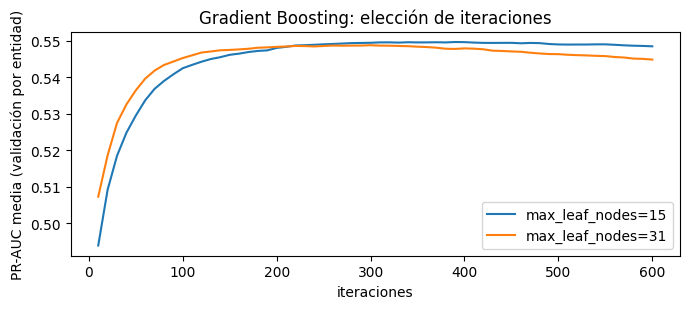

,max_leaf_nodes,iteraciones,PR-AUC media,error estándar
0,15,390,0.5497,0.0122
1,31,300,0.5488,0.0125


Gradient Boosting: PR-AUC fuera de pliegue 0.5503 · umbral F1 = 0.264


In [114]:
ITER_MAX, PASO = 600, 10
gb_base = dict(learning_rate=0.06, l2_regularization=1.0, categorical_features="from_dtype",
               early_stopping=False, random_state=SEMILLA)

def curva_gb(max_leaf_nodes):
    curvas, staged = [], []
    for a, v in PLIEGUES:
        m = HistGradientBoostingClassifier(max_iter=ITER_MAX, max_leaf_nodes=max_leaf_nodes, **gb_base)
        m.fit(Xc_tr.iloc[a], y_tr[a])
        ps = [pr[:, 1] for k, pr in enumerate(m.staged_predict_proba(Xc_tr.iloc[v]), 1) if k % PASO == 0]
        curvas.append([average_precision_score(y_tr[v], p) for p in ps])
        staged.append(ps)
    return np.array(curvas), staged

filas, mejor = [], None
fig, ax = plt.subplots(figsize=(7, 3.2))
for hojas in [15, 31]:
    curvas, staged = curva_gb(hojas)
    media = curvas.mean(axis=0)
    i = int(np.argmax(media))
    iters = (np.arange(len(media)) + 1) * PASO
    ax.plot(iters, media, label=f"max_leaf_nodes={hojas}")
    filas.append({"max_leaf_nodes": hojas, "iteraciones": int(iters[i]), "PR-AUC media": media[i],
                  "error estándar": curvas[:, i].std(ddof=1) / np.sqrt(len(PLIEGUES))})
    if mejor is None or media[i] > mejor["ap"]:
        oof = np.full(len(y_tr), np.nan)
        for (a, v), ps in zip(PLIEGUES, staged):
            oof[v] = ps[i]
        mejor = dict(ap=media[i], hojas=hojas, iters=int(iters[i]), oof=oof)
ax.set(xlabel="iteraciones", ylabel="PR-AUC media (validación por entidad)", title="Gradient Boosting: elección de iteraciones")
ax.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame(filas).round(4))

gb = HistGradientBoostingClassifier(max_iter=mejor["iters"], max_leaf_nodes=mejor["hojas"], **gb_base).fit(Xc_tr, y_tr)
p_gb = gb.predict_proba(Xc_te)[:, 1]
class BoostingConCategorias(ClassifierMixin, BaseEstimator):
    """Boosting que aprende los niveles de categoría en sus propios datos de ajuste y recibe X sin convertir."""
    def fit(self, Xa, ya):
        self.classes_ = np.array([0, 1])
        self.niveles = {c: Xa[c].value_counts().index[:250].tolist() for c in CATEGORICAS}
        self.modelo = HistGradientBoostingClassifier(max_iter=mejor["iters"], max_leaf_nodes=mejor["hojas"], **gb_base)
        self.modelo.fit(self._conv(Xa), ya)
        return self
    def _conv(self, D):
        return D.assign(**{c: pd.Categorical(D[c].where(D[c].isin(self.niveles[c]), "OTRA"),
                                             categories=self.niveles[c] + ["OTRA"]) for c in CATEGORICAS})
    def predict_proba(self, D):
        return self.modelo.predict_proba(self._conv(D))

registrar("Gradient Boosting", mejor["oof"], p_gb, gb, Xc_te,
          ajustar=lambda Xa, ya: BoostingConCategorias().fit(Xa, ya))

## 9. Red neuronal (perceptrón multicapa)

### 9.1 Qué hay que decidir y por qué

Una red no aprende su propia forma: la arquitectura, la regularización y la duración del entrenamiento se fijan desde afuera y se eligen con validación. Para este problema:

| Decisión | Elección | Razón |
|---|---|---|
| Entradas | one-hot + numéricas estandarizadas (`prep_lineal`) | la red combina las entradas con pesos; sin escalar, las variables de mayor magnitud dominan el gradiente |
| Arquitectura | `(32,)` y `(64, 32)` | con datos tabulares, una o dos capas suelen bastar; se prueba una pequeña y una mediana |
| Activación | ReLU (por defecto) | el gradiente no se encoge al pasar por las capas activas |
| Regularización L2 (`alpha`) | 1e-4 y 1e-2 | controla el tamaño de los pesos; frena la memorización |
| Optimizador | Adam, tasa de aprendizaje 1e-3, lotes de 256 | valores estándar y estables |
| Épocas | elegidas con validación **por entidad** | la parada temprana de `MLPClassifier` separa por filas; aquí se entrena época por época con `partial_fit` y se mide la PR-AUC en entidades que el pliegue no vio |
| Semillas | 3 semillas en el modelo final | los pesos iniciales son aleatorios; la variación entre semillas mide cuánto del resultado es azar |

Para no multiplicar el tiempo, la búsqueda usa los primeros 3 pliegues; las predicciones fuera de pliegue para el umbral usan los 5.

### 9.2 Calibración de las probabilidades

Una red entrenada con entropía cruzada y sin ponderar clases tiende a dar probabilidades razonablemente calibradas, pero conviene verificarlo: la sección 10 compara las curvas de calibración y el puntaje de Brier de todos los modelos. Si la red quedara mal calibrada y se necesitaran probabilidades (por ejemplo, para un umbral por costos), se recalibraría con `CalibratedClassifierCV` usando los mismos pliegues por entidad.

,arquitectura,alpha,mejor época,PR-AUC media,error estándar,PR-AUC última época
0,"(32,)",0.0001,6,0.5198,0.0238,0.4990
1,"(32,)",0.0100,8,0.5216,0.0237,0.5057
2,"(64, 32)",0.0001,3,0.5254,0.0262,0.4654
3,"(64, 32)",0.0100,4,0.5240,0.0273,0.4748


Búsqueda de la red: 229 s


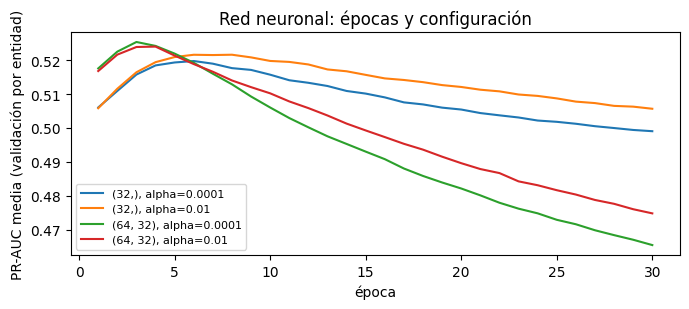

In [115]:
ARQUITECTURAS = [(32,), (64, 32)]
ALPHAS = [1e-4, 1e-2]
EPOCAS_MAX = 30
PLIEGUES_RED = PLIEGUES[:3]

def red_nueva(arq, alpha, semilla=SEMILLA):
    return MLPClassifier(hidden_layer_sizes=arq, alpha=alpha, learning_rate_init=1e-3,
                         batch_size=256, random_state=semilla)

def entrenar_por_epocas(red, Xa, ya, epocas, Xv=None, yv=None):
    aps = []
    for _ in range(epocas):
        red.partial_fit(Xa, ya, classes=np.array([0, 1]))
        if Xv is not None:
            aps.append(average_precision_score(yv, red.predict_proba(Xv)[:, 1]))
    return red, aps

t0 = time.time()
datos_red = []
for a, v in PLIEGUES_RED:                       # el preprocesamiento se ajusta dentro de cada pliegue
    prep = clone(prep_lineal).fit(X_tr.iloc[a])
    datos_red.append((prep.transform(X_tr.iloc[a]), y_tr[a], prep.transform(X_tr.iloc[v]), y_tr[v]))

filas, curvas_red = [], {}
for arq in ARQUITECTURAS:
    for alpha in ALPHAS:
        c = np.array([entrenar_por_epocas(red_nueva(arq, alpha), Xa, ya, EPOCAS_MAX, Xv, yv)[1]
                      for Xa, ya, Xv, yv in datos_red])
        curvas_red[(arq, alpha)] = c
        media = c.mean(axis=0); i = int(np.argmax(media))
        filas.append({"arquitectura": str(arq), "alpha": alpha, "mejor época": i + 1, "PR-AUC media": media[i],
                      "error estándar": c[:, i].std(ddof=1) / np.sqrt(len(c)), "PR-AUC última época": media[-1],
                      "_clave": (arq, alpha)})
tabla_red = pd.DataFrame(filas)
display(tabla_red.drop(columns="_clave").round(4))
print(f"Búsqueda de la red: {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(7, 3.2))
for (arq, alpha), c in curvas_red.items():
    ax.plot(np.arange(1, EPOCAS_MAX + 1), c.mean(axis=0), label=f"{arq}, alpha={alpha:g}")
ax.set(xlabel="época", ylabel="PR-AUC media (validación por entidad)", title="Red neuronal: épocas y configuración")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [116]:
fila = tabla_red.loc[tabla_red["PR-AUC media"].idxmax()]
(ARQ, ALPHA), EPOCAS = fila["_clave"], int(fila["mejor época"])
print(f"Red elegida: capas {ARQ}, alpha={ALPHA:g}, {EPOCAS} épocas")

# predicciones fuera de pliegue (los 5 pliegues) para el umbral
oof_red = np.full(len(y_tr), np.nan)
for a, v in PLIEGUES:
    prep = clone(prep_lineal).fit(X_tr.iloc[a])
    red, _ = entrenar_por_epocas(red_nueva(ARQ, ALPHA), prep.transform(X_tr.iloc[a]), y_tr[a], EPOCAS)
    oof_red[v] = red.predict_proba(prep.transform(X_tr.iloc[v]))[:, 1]

# modelo final con todo el entrenamiento y 3 semillas
prep_red = clone(prep_lineal).fit(X_tr)
Z_tr, Z_te = prep_red.transform(X_tr), prep_red.transform(X_te)
redes = {s: entrenar_por_epocas(red_nueva(ARQ, ALPHA, s), Z_tr, y_tr, EPOCAS)[0] for s in [SEMILLA, SEMILLA + 1, SEMILLA + 2]}
ap_semillas = {s: average_precision_score(y_te, r.predict_proba(Z_te)[:, 1]) for s, r in redes.items()}
red_final = redes[SEMILLA]
n_param = sum(w.size for w in red_final.coefs_) + sum(b.size for b in red_final.intercepts_)
print(f"Entradas tras one-hot: {Z_tr.shape[1]} · parámetros de la red: {n_param:,}")
print("PR-AUC en prueba según la semilla:", {s: round(v, 4) for s, v in ap_semillas.items()},
      f"· desviación {np.std(list(ap_semillas.values()), ddof=1):.4f}")

red_pipe = Pipeline([("prep", prep_red), ("clf", red_final)])   # pasos ya ajustados
def ajustar_red(Xa, ya):
    prep = clone(prep_lineal).fit(Xa)
    red, _ = entrenar_por_epocas(red_nueva(ARQ, ALPHA), prep.transform(Xa), ya, EPOCAS)
    return Pipeline([("prep", prep), ("clf", red)])

registrar("Red neuronal", oof_red, red_final.predict_proba(Z_te)[:, 1], red_pipe, X_te, ajustar=ajustar_red)

Red elegida: capas (64, 32), alpha=0.0001, 3 épocas
Entradas tras one-hot: 471 · parámetros de la red: 32,321
PR-AUC en prueba según la semilla: {42: 0.5348, 43: 0.5229, 44: 0.5269} · desviación 0.0060
Red neuronal: PR-AUC fuera de pliegue 0.5286 · umbral F1 = 0.249


## 10. Selección automática del campeón y comparación en prueba (contratos de 2024)

### 10.1 Regla de selección

La regla se fija antes de mirar la prueba y usa solo las predicciones **fuera de pliegue** del entrenamiento:

1. **Métrica principal:** PR-AUC media de la validación cruzada por entidad.
2. **Elegibles:** los modelos que quedan a menos de **un error estándar** del mejor. El error estándar se calcula sobre las diferencias pliegue a pliegue (comparación **pareada**: mismo pliegue, mismas entidades), que es más preciso que comparar las dos medias por separado. Además, cada elegible debe superar a la línea base por más de dos errores estándar.
3. **Entre los elegibles, el más interpretable:** nivel 1, regresión logística y árbol de decisión; nivel 2, bosque aleatorio y Gradient Boosting; nivel 3, red neuronal. Si el modelo más simple ordena igual de bien, se prefiere porque una contraloría puede explicar por qué marcó un contrato.
4. **Desempates dentro del mismo nivel:** menor puntaje de Brier fuera de pliegue (probabilidades más fieles a la frecuencia real) y, si persiste el empate, mayor precisión en el `CAPACIDAD` (10 %) de contratos con mayor puntaje, que es lo que vería un equipo con capacidad de revisión limitada.
5. **La prueba solo confirma.** Si la PR-AUC del campeón en 2024 cae más de max(0,03; 3 errores estándar) frente a la validación cruzada, se emite una advertencia. No se cambia de campeón con la prueba: si se eligiera con ella, dejaría de ser una prueba.

La estabilidad entre pliegues y el peor ROC-AUC por modalidad (fuera de pliegue) se muestran como información; no entran en la decisión.

In [117]:
NIVEL = {"Regresión logística": 1, "Árbol de decisión": 1, "Bosque aleatorio": 2, "Gradient Boosting": 2, "Red neuronal": 3}
PK = f"precisión@{CAPACIDAD:.0%}"
K = len(PLIEGUES)
ee = lambda d: d.std(ddof=1) / np.sqrt(len(d))   # error estándar de una media de pliegues

def ap_por_pliegue(p):
    return np.array([average_precision_score(y_tr[v], p[v]) for _, v in PLIEGUES])

def precision_en_k(yd, p, frac=CAPACIDAD):
    k = max(1, int(round(frac * len(yd))))
    return yd[np.argsort(-p, kind="stable")[:k]].mean()

mod_tr = df.modalidad_de_contratacion.values[tr]
def peor_auc_modalidad(p):
    v = [roc_auc_score(y_tr[s], p[s]) for s in (mod_tr == mod for mod in pd.unique(mod_tr))
         if s.sum() >= 200 and 0 < y_tr[s].mean() < 1]
    return min(v) if v else np.nan

AP = {n: ap_por_pliegue(m["p_oof"]) for n, m in MODELOS.items()}
candidatos = [n for n in MODELOS if n != "Línea base"]
MEJOR_CV = max(candidatos, key=lambda n: AP[n].mean())

filas = []
for n in candidatos:
    d_mejor = AP[MEJOR_CV] - AP[n]
    d_base = AP[n] - AP["Línea base"]
    cerca = (n == MEJOR_CV) or (d_mejor.mean() <= ee(d_mejor))
    sobre_base = d_base.mean() > 2 * ee(d_base)
    filas.append({"modelo": n, "PR-AUC CV": AP[n].mean(), "desv. entre pliegues": AP[n].std(ddof=1),
                  "Δ vs mejor": -d_mejor.mean(), "EE pareado": 0.0 if n == MEJOR_CV else ee(d_mejor),
                  "supera base": sobre_base, "elegible": cerca and sobre_base, "nivel": NIVEL.get(n, 3),
                  "Brier OOF": brier_score_loss(y_tr, MODELOS[n]["p_oof"]),
                  f"{PK} OOF": precision_en_k(y_tr, MODELOS[n]["p_oof"]),
                  "peor ROC-AUC por modalidad": peor_auc_modalidad(MODELOS[n]["p_oof"])})
seleccion = pd.DataFrame(filas).set_index("modelo")
elegibles = seleccion[seleccion.elegible]

if elegibles.empty:
    CAMPEON = MEJOR_CV
    print("ADVERTENCIA: ningún modelo supera a la línea base por más de dos errores estándar; "
          "se reporta el de mejor PR-AUC en validación, pero el modelo no aporta información útil.")
else:
    orden = elegibles.assign(_brier=elegibles["Brier OOF"], _pk=-elegibles[f"{PK} OOF"]).sort_values(["nivel", "_brier", "_pk"])
    CAMPEON = orden.index[0]
REFERENCIA = CAMPEON   # las secciones siguientes analizan al campeón

display(seleccion.sort_values("PR-AUC CV", ascending=False).round(4))
print(f"Mejor PR-AUC en validación cruzada: {MEJOR_CV} ({AP[MEJOR_CV].mean():.4f})")
print(f"Elegibles (a menos de 1 EE pareado del mejor y por encima de la base): {list(elegibles.index)}")
print(f"CAMPEÓN: {CAMPEON} (nivel de interpretabilidad {NIVEL.get(CAMPEON, 3)})")
if CAMPEON != MEJOR_CV:
    print(f"  Se prefiere a {MEJOR_CV} porque su PR-AUC no es distinguible dentro de un error estándar "
          f"(Δ {seleccion.loc[CAMPEON, 'Δ vs mejor']:+.4f}, EE {seleccion.loc[CAMPEON, 'EE pareado']:.4f}) y es más interpretable.")

,PR-AUC CV,desv. entre pliegues,Δ vs mejor,EE pareado,supera base,elegible,nivel,Brier OOF,precisión@10% OOF,peor ROC-AUC por modalidad
modelo,,,,,,,,,,
Gradient Boosting,0.5497,0.0274,-0.0000,0.0000,True,True,2,0.1537,0.6551,0.6626
Bosque aleatorio,0.5362,0.0305,-0.0135,0.0026,True,False,2,0.1561,0.6458,0.6340
Red neuronal,0.5286,0.0324,-0.0210,0.0026,True,False,3,0.1583,0.6389,0.6411
Regresión logística,0.5013,0.0286,-0.0483,0.0008,True,False,1,0.2024,0.6039,0.6378
Árbol de decisión,0.4712,0.0271,-0.0784,0.0037,True,False,1,0.1659,0.5789,0.5915


Mejor PR-AUC en validación cruzada: Gradient Boosting (0.5497)
Elegibles (a menos de 1 EE pareado del mejor y por encima de la base): ['Gradient Boosting']
CAMPEÓN: Gradient Boosting (nivel de interpretabilidad 2)


### 10.2 Comparación en prueba

Cada modelo usa el umbral elegido con sus predicciones fuera de pliegue. Las diferencias frente al campeón se miden con bootstrap **pareado por entidad**: en cada remuestreo se calculan las métricas de todos los modelos sobre las mismas entidades. La columna `precisión@10%` es la proporción de sobrecostos entre el 10 % de contratos con mayor puntaje.

In [ ]:
filas = []
for nombre, m in MODELOS.items():
    p, u = m["p_te"], m["umbral"]
    pred = p >= u
    filas.append({"modelo": nombre, "PR-AUC CV": AP[nombre].mean(),
                  "ROC-AUC": roc_auc_score(y_te, p), "PR-AUC": average_precision_score(y_te, p),
                  PK: precision_en_k(y_te, p),
                  "umbral": u, "precisión": precision_score(y_te, pred, zero_division=0),
                  "exhaustividad": recall_score(y_te, pred), "F1": f1_score(y_te, pred),
                  "% marcados": pred.mean(), "Brier": brier_score_loss(y_te, p)})
tabla = pd.DataFrame(filas).set_index("modelo")
display(tabla.round(3))

# confirmación del campeón en la prueba (no cambia la elección)
tolerancia = max(0.03, 3 * ee(AP[CAMPEON]))
caida = AP[CAMPEON].mean() - tabla.loc[CAMPEON, "PR-AUC"]
if caida > tolerancia:
    print(f"ADVERTENCIA: la PR-AUC del campeón cae {caida:.3f} de validación a prueba (tolerancia {tolerancia:.3f}). "
          "Puede haber un cambio entre años; revisar la sección 12.2 antes de usar el modelo.")
else:
    print(f"Confirmación: la PR-AUC del campeón en prueba ({tabla.loc[CAMPEON, 'PR-AUC']:.3f}) está dentro de la "
          f"tolerancia frente a la validación cruzada ({AP[CAMPEON].mean():.3f}; tolerancia {tolerancia:.3f}).")

# bootstrap pareado por entidad
rng = np.random.default_rng(SEMILLA)
pos_por_entidad = pd.Series(np.arange(len(y_te))).groupby(g_te).indices
entidades = np.array(list(pos_por_entidad))
boot = {n: {"ap": [], "auc": []} for n in MODELOS}
for _ in range(N_BOOT):
    ii = np.concatenate([pos_por_entidad[e] for e in rng.choice(entidades, len(entidades), replace=True)])
    if y_te[ii].min() == y_te[ii].max():
        continue
    for n, m in MODELOS.items():
        boot[n]["ap"].append(average_precision_score(y_te[ii], m["p_te"][ii]))
        boot[n]["auc"].append(roc_auc_score(y_te[ii], m["p_te"][ii]))
boot = {n: {k: np.array(v) for k, v in d.items()} for n, d in boot.items()}

ic = pd.DataFrame({n: {"PR-AUC": f"{np.median(d['ap']):.3f} [{np.percentile(d['ap'], 2.5):.3f}, {np.percentile(d['ap'], 97.5):.3f}]",
                       "ROC-AUC": f"{np.median(d['auc']):.3f} [{np.percentile(d['auc'], 2.5):.3f}, {np.percentile(d['auc'], 97.5):.3f}]",
                       f"Δ PR-AUC vs {CAMPEON}": "—" if n == CAMPEON else
                           f"{np.median(d['ap'] - boot[CAMPEON]['ap']):+.3f} "
                           f"[{np.percentile(d['ap'] - boot[CAMPEON]['ap'], 2.5):+.3f}, "
                           f"{np.percentile(d['ap'] - boot[CAMPEON]['ap'], 97.5):+.3f}]"}
                   for n, d in boot.items()}).T
print(f"\nIntervalos de 95 % (bootstrap por entidad, {len(boot[CAMPEON]['ap'])} remuestreos):")
display(ic)
print("Una diferencia cuyo intervalo no contiene 0 es distinguible del azar de qué entidades tocan en la prueba.")

print("\nPrueba según si la entidad ya contrataba en el período de entrenamiento:")
print(f"  tasa de sobrecosto: entidades conocidas {y_te[~ENTIDAD_NUEVA].mean():.3f} ({(~ENTIDAD_NUEVA).sum():,} contratos) · "
      f"nuevas {y_te[ENTIDAD_NUEVA].mean():.3f} ({ENTIDAD_NUEVA.sum():,} contratos)")
filas = {}
for n, m in MODELOS.items():
    fila = {}
    for etiqueta, s in [("conocidas", ~ENTIDAD_NUEVA), ("nuevas", ENTIDAD_NUEVA)]:
        ok = 0 < y_te[s].mean() < 1
        fila[f"PR-AUC {etiqueta}"] = average_precision_score(y_te[s], m["p_te"][s]) if ok else np.nan
        fila[f"PR-AUC / tasa {etiqueta}"] = fila[f"PR-AUC {etiqueta}"] / y_te[s].mean() if ok else np.nan
        fila[f"ROC-AUC {etiqueta}"] = roc_auc_score(y_te[s], m["p_te"][s]) if ok else np.nan
    filas[n] = fila
display(pd.DataFrame(filas).T.round(3))
print("La PR-AUC depende de la tasa de positivos de cada grupo; para comparar grupos, mirar PR-AUC / tasa (cuántas veces "
      "supera al azar) o el ROC-AUC, que no depende de la tasa.")

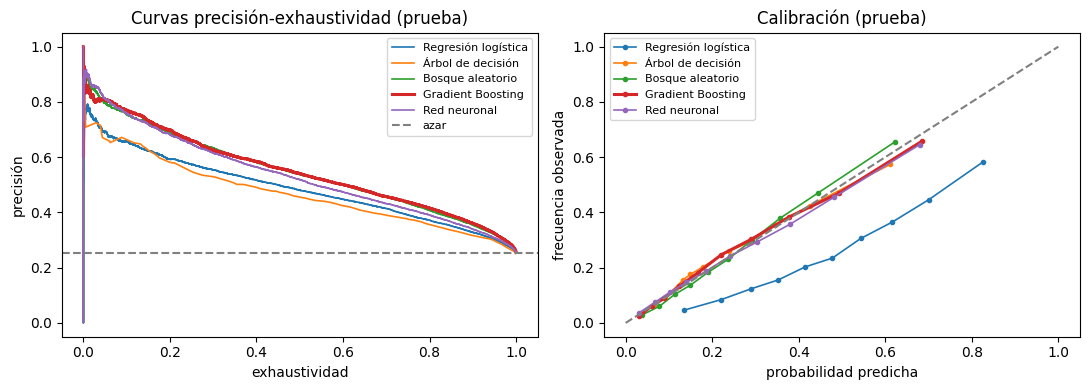

Matriz de confusión del campeón (Gradient Boosting) con umbral 0.264 [filas = real, columnas = predicho]:
[[36684 14164]
 [ 5331 12044]]


In [119]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for nombre, m in MODELOS.items():
    if nombre == "Línea base":
        continue
    prec, rec, _ = precision_recall_curve(y_te, m["p_te"])
    axes[0].plot(rec, prec, label=nombre, lw=2.2 if nombre == CAMPEON else 1.2)
    frac, media = calibration_curve(y_te, m["p_te"], n_bins=10, strategy="quantile")
    axes[1].plot(media, frac, marker="o", ms=3, label=nombre, lw=2.2 if nombre == CAMPEON else 1.2)
axes[0].axhline(y_te.mean(), color="gray", ls="--", label="azar")
axes[0].set(xlabel="exhaustividad", ylabel="precisión", title="Curvas precisión-exhaustividad (prueba)")
axes[1].plot([0, 1], [0, 1], color="gray", ls="--")
axes[1].set(xlabel="probabilidad predicha", ylabel="frecuencia observada", title="Calibración (prueba)")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

m = MODELOS[CAMPEON]
print(f"Matriz de confusión del campeón ({CAMPEON}) con umbral {m['umbral']:.3f} [filas = real, columnas = predicho]:")
print(confusion_matrix(y_te, m["p_te"] >= m["umbral"]))

In [120]:
print(f"Desempeño del campeón ({CAMPEON}) por modalidad (prueba, modalidades con al menos 200 contratos):")
mod_te = df.modalidad_de_contratacion.values[te]
filas = []
for mod in pd.unique(mod_te):
    s = mod_te == mod
    if s.sum() >= 200 and 0 < y_te[s].mean() < 1:
        filas.append({"modalidad": mod, "contratos": int(s.sum()), "tasa": y_te[s].mean(),
                      "PR-AUC": average_precision_score(y_te[s], m["p_te"][s]),
                      "ROC-AUC": roc_auc_score(y_te[s], m["p_te"][s])})
display(pd.DataFrame(filas).sort_values("contratos", ascending=False).set_index("modalidad").round(3))
print("Si el ROC-AUC dentro de cada modalidad es mucho menor que el global, parte del desempeño viene de "
      "distinguir modalidades con tasas distintas, no de ordenar contratos dentro de cada una.")

Desempeño del campeón (Gradient Boosting) por modalidad (prueba, modalidades con al menos 200 contratos):


,contratos,tasa,PR-AUC,ROC-AUC
modalidad,,,,
Mínima cuantía,40229,0.209,0.472,0.774
Contratación Directa (con ofertas),8285,0.228,0.504,0.771
Selección Abreviada de Menor Cuantía,6716,0.412,0.653,0.735
Contratación régimen especial (con ofertas),4990,0.268,0.503,0.754
Selección abreviada subasta inversa,4947,0.325,0.630,0.794
Licitación pública,1185,0.601,0.823,0.789
Concurso de méritos abierto,1168,0.271,0.499,0.736
Licitación pública Obra Publica,574,0.533,0.641,0.639


Si el ROC-AUC dentro de cada modalidad es mucho menor que el global, parte del desempeño viene de distinguir modalidades con tasas distintas, no de ordenar contratos dentro de cada una.


### 10.3 Curva de aprendizaje: ¿más datos de entrenamiento cambiarían el resultado?

El entrenamiento usa tres años completos y la prueba el cuarto, así que la proporción entrenamiento/prueba la fija el calendario y no un 80/20 elegido a mano. Para verificar que la cantidad de datos no limita al campeón, se reentrena (con los hiperparámetros ya elegidos) con el 25 %, 50 % y 75 % de las **entidades** de entrenamiento, dos veces cada fracción, y se mide la PR-AUC en 2024; el punto del 100 % es el modelo final. Si la curva ya está plana entre el 75 % y el 100 %, agregar más datos no la movería de forma apreciable. Es un diagnóstico: no cambia ninguna decisión.

,contratos,media,desviacion
fracción,,,
0.25,43055.5,0.5149,0.0002
0.50,87880.5,0.5265,0.0150
0.75,136583.5,0.5416,0.0015
1.00,177071.0,0.5510,NaN


Curva de aprendizaje: 42 s


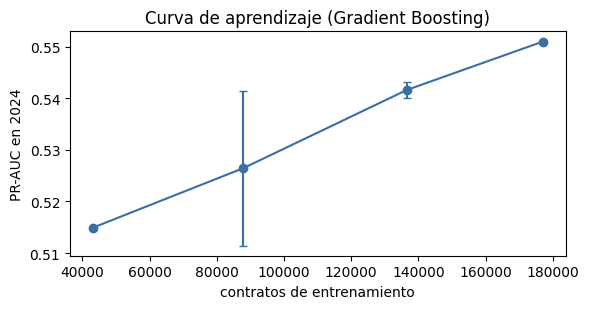

Pasar del 75 % al 100 % del entrenamiento cambia la PR-AUC en +0.0094.
Si esa ganancia es pequeña frente al ancho del intervalo de confianza de la sección 10.2, entrenar con más datos no cambiaría el resultado de forma apreciable.


In [121]:
FRACCIONES, REPETICIONES = [0.25, 0.5, 0.75], 2
rng_curva = np.random.default_rng(SEMILLA)
ent_tr = np.unique(g_tr)
ajustar_campeon = MODELOS[CAMPEON]["ajustar"]
t0 = time.time()
filas = []
for f in FRACCIONES:
    for _ in range(REPETICIONES):
        elegidas = rng_curva.choice(ent_tr, int(round(f * len(ent_tr))), replace=False)
        s = np.where(np.isin(g_tr, elegidas))[0]
        mod = ajustar_campeon(X_tr.iloc[s], y_tr[s])
        filas.append({"fracción": f, "contratos": len(s),
                      "PR-AUC prueba": average_precision_score(y_te, mod.predict_proba(X_te)[:, 1])})
filas.append({"fracción": 1.0, "contratos": len(y_tr), "PR-AUC prueba": average_precision_score(y_te, MODELOS[CAMPEON]["p_te"])})
curva = (pd.DataFrame(filas).groupby("fracción")
         .agg(contratos=("contratos", "mean"), media=("PR-AUC prueba", "mean"), desviacion=("PR-AUC prueba", "std")))
display(curva.round(4))
print(f"Curva de aprendizaje: {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.errorbar(curva.contratos, curva.media, yerr=curva.desviacion.fillna(0), marker="o", capsize=3, color="#3b6ea5")
ax.set(xlabel="contratos de entrenamiento", ylabel=f"PR-AUC en {ANIO_PRUEBA}", title=f"Curva de aprendizaje ({CAMPEON})")
plt.tight_layout(); plt.show()

ganancia = curva.loc[1.0, "media"] - curva.loc[0.75, "media"]
print(f"Pasar del 75 % al 100 % del entrenamiento cambia la PR-AUC en {ganancia:+.4f}.")
print("Si esa ganancia es pequeña frente al ancho del intervalo de confianza de la sección 10.2, "
      "entrenar con más datos no cambiaría el resultado de forma apreciable.")

## 11. Importancia de variables del campeón (permutación sobre el conjunto de prueba)

Se permuta cada variable y se mide cuánto cae la PR-AUC del campeón. Mide cuánto **depende este modelo** de cada variable, no si la variable causa el sobrecosto; con variables correlacionadas (precio base y valor adjudicado), la importancia se reparte entre ellas.

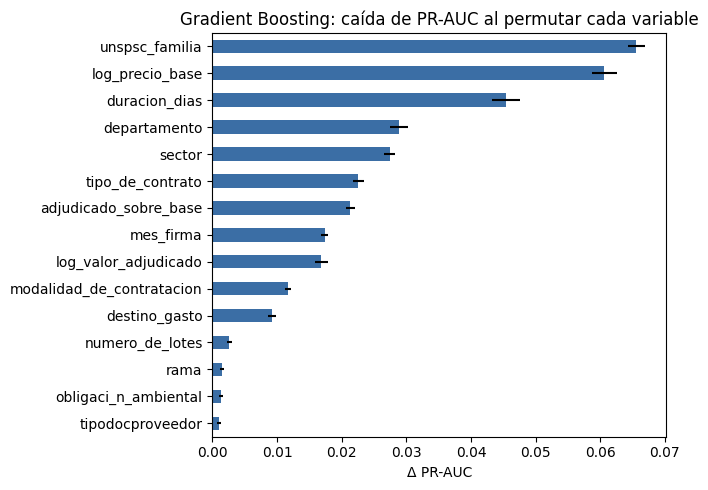

Cinco variables más importantes: ['unspsc_familia', 'log_precio_base', 'duracion_dias', 'departamento', 'sector']


In [122]:
m = MODELOS[CAMPEON]
imp = permutation_importance(m["predictor"], m["X_prueba"], y_te, scoring="average_precision",
                             n_repeats=5, random_state=SEMILLA, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=m["X_prueba"].columns).sort_values()
ax = importancia.tail(15).plot.barh(figsize=(7, 5), color="#3b6ea5",
                                    xerr=pd.Series(imp.importances_std, index=m["X_prueba"].columns)[importancia.tail(15).index])
ax.set(title=f"{CAMPEON}: caída de PR-AUC al permutar cada variable", xlabel="Δ PR-AUC")
plt.tight_layout(); plt.show()
TOP_PRINCIPAL = importancia.sort_values(ascending=False).head(5).index.tolist()
print("Cinco variables más importantes:", TOP_PRINCIPAL)

## 12. Robustez

Se reentrenan el campeón y la regresión logística (como referencia simple) con los hiperparámetros ya elegidos, cambiando una cosa a la vez:

* **12.1 Corte del objetivo:** los dos escenarios de la sección 4.2 (nominal y legal), con la misma partición 2021-2023 contra 2024. Si el desempeño y las cinco variables principales del campeón coinciden, la conclusión no depende de cómo se limpió el objetivo.
* **12.2 Año de prueba:** segunda ventana temporal (`VENTANA_2`: entrenar 2021-2022 y evaluar 2023) con el objetivo principal. Si el nivel de desempeño y la diferencia entre el campeón y la logística se mantienen, el resultado no depende de un solo año. Aviso: los hiperparámetros se eligieron con validación cruzada que incluía 2023, así que esta ventana no es una prueba totalmente independiente; sirve para ver la estabilidad entre años, no para reportar un desempeño.

In [123]:
MODELOS_ROBUSTEZ = list(dict.fromkeys([CAMPEON, "Regresión logística"]))

def ajuste_rapido(d, anios_a, anio_b):
    Xa, ya = construir_X(d), d.sobrecosto.values
    a = np.where(np.isin(d.anio_firma.values, anios_a))[0]
    b = np.where(d.anio_firma.values == anio_b)[0]
    fila = {"contratos entren.": len(a), "contratos prueba": len(b), "tasa prueba": round(ya[b].mean(), 3)}
    for n in MODELOS_ROBUSTEZ:
        mod = MODELOS[n]["ajustar"](Xa.iloc[a], ya[a])
        p = mod.predict_proba(Xa.iloc[b])[:, 1]
        fila[f"PR-AUC {n}"] = round(average_precision_score(ya[b], p), 3)
        fila[f"ROC-AUC {n}"] = round(roc_auc_score(ya[b], p), 3)
        if n == CAMPEON:
            im = permutation_importance(mod, Xa.iloc[b], ya[b], scoring="average_precision",
                                        n_repeats=3, random_state=SEMILLA, n_jobs=-1)
            fila["top 5 (campeón)"] = pd.Series(im.importances_mean, index=Xa.columns).sort_values(ascending=False).head(5).index.tolist()
    return fila

t0 = time.time()
ventana_1 = f"{ANIOS_ENTRENAMIENTO[0]}-{ANIOS_ENTRENAMIENTO[-1]} → {ANIO_PRUEBA}"
ventana_2 = f"{VENTANA_2[0][0]}-{VENTANA_2[0][-1]} → {VENTANA_2[1]}"
robustez = pd.DataFrame({
    f"12.1 objetivo nominal · {ventana_1}": ajuste_rapido(ESCENARIOS["nominal"], ANIOS_ENTRENAMIENTO, ANIO_PRUEBA),
    f"12.1 objetivo legal · {ventana_1}": ajuste_rapido(ESCENARIOS["legal"], ANIOS_ENTRENAMIENTO, ANIO_PRUEBA),
    f"12.2 objetivo {CORTE_PRINCIPAL} · {ventana_2}": ajuste_rapido(ESCENARIOS[CORTE_PRINCIPAL], *VENTANA_2),
}).T
display(robustez)
print(f"Robustez: {time.time() - t0:.0f} s")

f_nom, f_leg, f_v2 = robustez.index
comunes = set(robustez.loc[f_nom, "top 5 (campeón)"]) & set(robustez.loc[f_leg, "top 5 (campeón)"])
comunes_v2 = set(robustez.loc[f_v2, "top 5 (campeón)"]) & set(robustez.loc[f"12.1 objetivo {CORTE_PRINCIPAL} · {ventana_1}", "top 5 (campeón)"])
print(f"12.1 · variables en el top 5 de ambos escenarios del objetivo: {len(comunes)} de 5 -> {sorted(comunes)}")
print(f"12.2 · variables en el top 5 de ambas ventanas temporales: {len(comunes_v2)} de 5 -> {sorted(comunes_v2)}")
pr_v1 = robustez.loc[f"12.1 objetivo {CORTE_PRINCIPAL} · {ventana_1}", f"PR-AUC {CAMPEON}"]
pr_v2 = robustez.loc[f_v2, f"PR-AUC {CAMPEON}"]
print(f"12.2 · PR-AUC del campeón: {pr_v1:.3f} ({ventana_1}) frente a {pr_v2:.3f} ({ventana_2})")
if CAMPEON != "Regresión logística":
    for f in (f"12.1 objetivo {CORTE_PRINCIPAL} · {ventana_1}", f_v2):
        print(f"       ventaja del campeón sobre la logística en {f.split('· ')[-1]}: "
              f"{robustez.loc[f, f'PR-AUC {CAMPEON}'] - robustez.loc[f, 'PR-AUC Regresión logística']:+.3f}")

,contratos entren.,contratos prueba,tasa prueba,PR-AUC Gradient Boosting,ROC-AUC Gradient Boosting,top 5 (campeón),PR-AUC Regresión logística,ROC-AUC Regresión logística
12.1 objetivo nominal · 2021-2023 → 2024,175523,67815,0.25,0.544,0.781,"[unspsc_familia, log_precio_base, duracion_dia...",0.477,0.74
12.1 objetivo legal · 2021-2023 → 2024,177071,68223,0.255,0.551,0.783,"[unspsc_familia, log_precio_base, duracion_dia...",0.487,0.742
12.2 objetivo legal · 2021-2022 → 2023,111914,65157,0.264,0.566,0.786,"[unspsc_familia, log_precio_base, duracion_dia...",0.514,0.75


Robustez: 252 s
12.1 · variables en el top 5 de ambos escenarios del objetivo: 5 de 5 -> ['departamento', 'duracion_dias', 'log_precio_base', 'sector', 'unspsc_familia']
12.2 · variables en el top 5 de ambas ventanas temporales: 5 de 5 -> ['departamento', 'duracion_dias', 'log_precio_base', 'sector', 'unspsc_familia']
12.2 · PR-AUC del campeón: 0.551 (2021-2023 → 2024) frente a 0.566 (2021-2022 → 2023)
       ventaja del campeón sobre la logística en 2021-2023 → 2024: +0.064
       ventaja del campeón sobre la logística en 2021-2022 → 2023: +0.052


## 13. ¿Cuánto infla la fuga de información las métricas?

Se usa el Gradient Boosting (sea o no el campeón), con la misma partición, agregando columnas con fuga: el efecto se ve igual en cualquier modelo flexible. Estas cifras **no son válidas**: se muestran para justificar la exclusión.

In [ ]:
def evaluar(nombre, p, umbral):
    return {"modelo": nombre, "ROC-AUC": roc_auc_score(y_te, p),
            "PR-AUC": average_precision_score(y_te, p), "F1": f1_score(y_te, p >= umbral)}

def con_extras(extras):
    A, B = Xc_tr.copy(), Xc_te.copy()
    for nombre, serie in extras.items():
        A[nombre], B[nombre] = serie.iloc[tr].values, serie.iloc[te].values
    mod = HistGradientBoostingClassifier(max_iter=mejor["iters"], max_leaf_nodes=mejor["hojas"], **gb_base).fit(A, y_tr)
    return mod.predict_proba(B)[:, 1]

u_gb = MODELOS["Gradient Boosting"]["umbral"]
fuga = {
    "estado_contrato": df.estado_contrato.astype("category"),
    "dias_adicionados": num(df.dias_adicionados),
    "fuente_pgn": num(df.presupuesto_general_de_la_nacion_pgn),
    "fuente_recursos_propios": num(df.recursos_propios),
    "duracion_por_fechas": dur_fechas,
}
comparacion = pd.DataFrame([
    evaluar("Limpio (al adjudicar)", p_gb, u_gb),
    evaluar("+ fuga (estado, días adicionados, fuentes, fechas)", con_extras(fuga), u_gb),
    evaluar("+ fuga total (valor_del_contrato)", con_extras({**fuga, "log_valor_final": np.log1p(df.valor_final)}), u_gb),
]).set_index("modelo").round(3)
comparacion

## 14. Conclusiones

In [124]:
t = tabla.drop(index="Línea base")
d_ref = {n: boot[n]["ap"] - boot[CAMPEON]["ap"] for n in MODELOS if n not in ("Línea base", CAMPEON)}
empatados = [n for n, d in d_ref.items() if np.percentile(d, 2.5) <= 0 <= np.percentile(d, 97.5)]
print(f"Diseño: entrenamiento {ANIOS_ENTRENAMIENTO} ({len(tr):,} contratos) · prueba {ANIO_PRUEBA} ({len(te):,} contratos) · solo contratos terminados")
print(f"Cobertura: el modelo aplica a modalidades que suman el {COBERTURA:.1%} de los contratos del período (sin la contratación directa ni el régimen especial sin ofertas)")
print(f"Escenario del objetivo: {CORTE_PRINCIPAL} · {len(df):,} contratos · tasa de sobrecosto {df.sobrecosto.mean():.1%}")
print(f"Campeón (regla automática, sección 10.1): {CAMPEON} · mejor en validación: {MEJOR_CV} · elegibles: {list(elegibles.index)}")
print(f"  PR-AUC CV {AP[CAMPEON].mean():.3f} · prueba: PR-AUC {t.loc[CAMPEON, 'PR-AUC']:.3f}, ROC-AUC {t.loc[CAMPEON, 'ROC-AUC']:.3f} "
      f"(línea base PR-AUC {tabla.loc['Línea base', 'PR-AUC']:.3f})")
print(f"  En el {CAPACIDAD:.0%} de contratos con mayor puntaje, el {t.loc[CAMPEON, PK]:.0%} tuvo sobrecosto (tasa general {y_te.mean():.0%})")
print(f"  Con su umbral F{BETA:g}: precisión {t.loc[CAMPEON, 'precisión']:.0%}, exhaustividad {t.loc[CAMPEON, 'exhaustividad']:.0%}, "
      f"marca al {t.loc[CAMPEON, '% marcados']:.0%} de los contratos")
print(f"Modelos no distinguibles del campeón en PR-AUC de prueba (bootstrap por entidad): {empatados or 'ninguno'}")
print(f"Variables principales del campeón: {TOP_PRINCIPAL}")
print("Texto libre: no usado (ver sección 5.1)")
print(f"Curva de aprendizaje: del 75 % al 100 % del entrenamiento la PR-AUC cambia {ganancia:+.4f}")
print(f"Robustez al corte del objetivo: {len(comunes)} de 5 variables principales coinciden entre escenarios")
print(f"Segunda ventana temporal ({ventana_2}): PR-AUC del campeón {pr_v2:.3f} frente a {pr_v1:.3f} en la ventana principal; "
      f"{len(comunes_v2)} de 5 variables principales coinciden")

Diseño: entrenamiento [2021, 2022, 2023] (177,071 contratos) · prueba 2024 (68,223 contratos) · solo contratos terminados
Cobertura: el modelo aplica a modalidades que suman el 9.5% de los contratos del período (sin la contratación directa ni el régimen especial sin ofertas)
Escenario del objetivo: legal · 245,294 contratos · tasa de sobrecosto 25.5%
Campeón (regla automática, sección 10.1): Gradient Boosting · mejor en validación: Gradient Boosting · elegibles: ['Gradient Boosting']
  PR-AUC CV 0.550 · prueba: PR-AUC 0.551, ROC-AUC 0.783 (línea base PR-AUC 0.255)
  En el 10% de contratos con mayor puntaje, el 66% tuvo sobrecosto (tasa general 25%)
  Con su umbral F1: precisión 46%, exhaustividad 69%, marca al 38% de los contratos
Modelos no distinguibles del campeón en PR-AUC de prueba (bootstrap por entidad): ['Bosque aleatorio']
Variables principales del campeón: ['unspsc_familia', 'log_precio_base', 'duracion_dias', 'departamento', 'sector']
Texto libre: no usado (ver sección 5.1)


### Conclusiones del diseño

* La llave entre las dos tablas es `proceso_de_compra` ↔ `id_del_portafolio`, y la variable objetivo es `valor_del_contrato > valor_total_adjudicacion`; la sección 4.3 la contrasta con el conjunto de adiciones.
* Solo entran contratos **terminados**, así que la etiqueta no puede cambiar después de la descarga.
* El tope legal de adiciones se mide en salarios mínimos, con el año de la última modificación tomado del conjunto de adiciones; un corte fijo de 1,5x en pesos descartaba contratos legales. La sección 12.1 muestra si eso cambia las conclusiones.
* Varias columnas aparentemente inocentes tienen **fuga**: las fuentes de financiación suman el valor final, las fechas de fin se mueven con las prórrogas y algunas cláusulas pueden actualizarse después de firmar (sección 4.4). Incluirlas infla el desempeño (sección 13).
* Todas las decisiones (hiperparámetros, iteraciones, épocas, umbrales y **el campeón**) se toman con validación cruzada **por entidad** dentro de 2021-2023, con una regla fijada de antemano que prefiere el modelo más interpretable cuando la diferencia no es distinguible. La prueba es un **año posterior** (2024), se usa una sola vez para confirmar y sus diferencias se leen con intervalos de bootstrap por entidad.

### Limitaciones

1. **Cobertura: el modelo no aplica a la contratación directa ni al régimen especial sin ofertas.** Esas modalidades no tienen valor adjudicado en *Procesos* (sección 4.5) y son cerca del 90 % de los contratos del período (`COBERTURA` da la cifra exacta). El conjunto de adiciones no trae montos, así que tampoco permite reconstruir su valor inicial. El modelo responde la pregunta para las modalidades competitivas y las variantes «con ofertas».
2. **Sesgo por exigir contratos terminados.** Los contratos que siguen vigentes, muchas veces por prórrogas, quedan fuera, y su tasa parcial de sobrecosto tiende a ser mayor (sección 4.1). El efecto es mayor en 2024, el año de prueba, porque sus contratos han tenido menos tiempo para terminar: la prueba representa mejor a los contratos cortos. Incluir contratos vigentes solo cuando ya tienen sobrecosto no lo corrige: seleccionaría filas según el resultado y sesgaría la tasa hacia arriba.
3. **Solo procesos con un único contrato.** Los procesos con varios lotes quedan fuera porque el valor adjudicado total no se puede repartir entre sus contratos; suelen ser compras más grandes y complejas, y no se sabe si el modelo funciona igual con ellos.
4. **La validación del objetivo es parcial.** El conjunto de adiciones clasifica sus registros de forma irregular y no trae montos: confirma que los contratos sin sobrecosto casi no tienen modificaciones de valor, pero no permite verificar uno por uno el monto de cada adición.
5. **El tope legal es una aproximación.** El año de la última adición se toma del último registro de modificación de valor o general; si el contrato no tiene registros, se usa el año de fin como cota superior. Para el régimen especial, que no tiene tope legal, el umbral de `TOPE_ERROR` es arbitrario.
6. **Dos ventanas temporales, no más, y prácticas de registro que cambian.** La prueba principal es 2024 y la segunda ventana (2023) comparte hiperparámetros elegidos con datos que la incluyen. Las prácticas de registro cambian entre años: la deriva de `liquidaci_n` (sección 4.4) y el aumento de contratos con UNSPSC `UNSPECIFIED` desde 2023 (sección 5.3) son dos ejemplos. Un cambio así podría bajar el desempeño; conviene reevaluar el modelo cada año.
7. **Variables que faltan:** el historial de la entidad y del proveedor (por ejemplo, su tasa de sobrecosto en contratos anteriores), calculado solo con contratos previos a cada firma, y el texto libre del objeto y la descripción, que se dejó fuera porque en parte identifica a la entidad y algunos registros se editan después de firmar (sección 5.1).
8. **Importancia no es causalidad**, y variables correlacionadas (precio base y valor adjudicado) se reparten la importancia.
9. **El umbral no incorpora costos reales:** el umbral F-beta puede marcar una fracción grande de los contratos; para operar es más natural revisar un número fijo de contratos (la `precisión@10%` de la sección 10.2) o fijar el umbral por el costo de cada error.
10. **La regla del campeón es una convención.** Los niveles de interpretabilidad y el margen de un error estándar son decisiones razonables, pero otras reglas (por ejemplo, ignorar la interpretabilidad) podrían elegir otro modelo; la tabla de la sección 10.1 permite ver qué pasaría. Además, el error estándar entre pliegues subestima algo la incertidumbre, porque los pliegues comparten datos de entrenamiento (la corrección de Nadeau y Bengio lo multiplicaría por cerca de 1,5); con esa corrección el resultado de esta corrida no cambia.

**Trabajo futuro:** reevaluar en ventanas temporales sucesivas a medida que terminen los contratos de 2025 y 2026; usar el campeón para **priorizar contratos vigentes** que aún no tienen adiciones; incorporar el historial de la entidad y del proveedor (solo con contratos anteriores); evaluar el texto libre controlando que no funcione como identificador de la entidad; y, para la contratación directa, validar si el precio base del proceso sirve como valor inicial.